In [1]:
import torch
import torchvision
from torch import nn, optim
from torch.nn import functional as F
import matplotlib.pyplot as plt
from pylab import rcParams
import numpy as np
import os
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Set up plotting parameters
rcParams['figure.figsize'] = 8, 8
plt.ion()  # Interactive plotting

print("✅ All libraries imported successfully!")
print(f"PyTorch version: {torch.__version__}")
print(f"Using device: {'CUDA' if torch.cuda.is_available() else 'CPU'}")


✅ All libraries imported successfully!
PyTorch version: 2.15.0+cu132
Using device: CUDA


In [2]:
# Training configuration
BATCH_SIZE = 128        # How many data points to process at once
EPOCHS = 100           # How many times to see the entire dataset
LOG_INTERVAL = 50      # How often to print progress updates

# Model architecture
INPUT_DIM = 28 * 28    # Our data has 2 dimensions (x, y coordinates)
NOISE_DIM = 32          # Dimension of noise input to generator
HIDDEN_DIM = 2048      # Size of hidden layers in our neural networks

# GAN-specific hyperparameters
LR_G = 8e-4           # Learning rate for Generator
LR_D = 2e-4           # Learning rate for Discriminator
BETA1 = 0.5           # Beta1 for Adam optimizer

# Visualization settings
SAVE_PLT_INTERVAL = 5   # How often to save plots (every 5 epochs)

# Set up device (use GPU if available, otherwise CPU)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print(f"Batch size: {BATCH_SIZE}")
print(f"Epochs: {EPOCHS}")
print(f"Hidden dimension: {HIDDEN_DIM}")
print(f"Generator learning rate: {LR_G}")
print(f"Discriminator learning rate: {LR_D}")
print(f"Device: {device}")


Batch size: 128
Epochs: 100
Hidden dimension: 2048
Generator learning rate: 0.0008
Discriminator learning rate: 0.0002
Device: cuda


In [3]:
train_data = torchvision.datasets.MNIST(
    root='data/',
    train=True,
    download=True,
    transform=torchvision.transforms.Compose([torchvision.transforms.ToTensor(), torch.flatten])
)
test_data = torchvision.datasets.MNIST(
    root='data/',
    train=False,
    download=True,
    transform=torchvision.transforms.Compose([torchvision.transforms.ToTensor(), torch.flatten])
)

print(f"Training data shape: {train_data.data.shape}")
print(f"Test data shape: {test_data.data.shape}")

Training data shape: torch.Size([60000, 28, 28])
Test data shape: torch.Size([10000, 28, 28])


In [4]:
# Set up data loaders
# pin_memory=True speeds up data transfer to GPU (if available)
kwargs = {'num_workers': 4, 'pin_memory': True} if device.type == 'cuda' else {}

train_loader = torch.utils.data.DataLoader(
    train_data,
    batch_size=BATCH_SIZE,
    shuffle=True,
    **kwargs
)

test_loader = torch.utils.data.DataLoader(
    test_data,
    batch_size=BATCH_SIZE,
    shuffle=True,
    **kwargs
)

print(f"Batch size: {BATCH_SIZE}")
print(f"Training batches: {len(train_loader)}")
print(f"Test batches: {len(test_loader)}")

Batch size: 128
Training batches: 469
Test batches: 79


In [5]:
class Generator(nn.Module):
    """
    Generator network that creates fake data from random noise.
    
    The Generator takes random noise as input and transforms it into
    data that should look like our real moon-shaped data.
    """
    
    def __init__(self, noise_dim, output_dim, hidden_dim):
        super().__init__()
        
        # Build the neural network layers
        self.net = nn.Sequential(
            # Input layer: noise -> hidden
            nn.Linear(noise_dim, hidden_dim),
            nn.ReLU(),
            
            # Hidden layers
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            
            # Output layer: hidden -> data
            nn.Linear(hidden_dim, output_dim),
            # No activation on output - we want raw coordinates
        )
    
    def forward(self, noise):
        """
        Transform noise into fake data.
        
        Args:
            noise: Random noise tensor of shape (batch_size, noise_dim)
        
        Returns:
            fake_data: Generated data of shape (batch_size, output_dim)
        """
        return self.net(noise)


In [6]:
class Discriminator(nn.Module):
    """
    Discriminator network that distinguishes between real and fake data.
    
    The Discriminator takes data (real or fake) as input and outputs
    a probability that the data is real (closer to 1) or fake (closer to 0).
    """
    
    def __init__(self, input_dim, hidden_dim):
        super().__init__()
        
        # Build the neural network layers
        self.net = nn.Sequential(
            # Input layer: data -> hidden
            nn.Linear(input_dim, hidden_dim),
            nn.LeakyReLU(0.2),  # LeakyReLU helps with gradient flow
            
            nn.Linear(hidden_dim, hidden_dim),
            nn.LeakyReLU(0.2),

            nn.Linear(hidden_dim, hidden_dim),
            nn.LeakyReLU(0.2),
            
            # Output layer: hidden -> probability
            nn.Linear(hidden_dim, 1),
            nn.Sigmoid()  # Output probability between 0 and 1
        )
    
    def forward(self, data):
        """
        Classify data as real or fake.
        
        Args:
            data: Input data tensor of shape (batch_size, input_dim)
        
        Returns:
            probability: Probability that data is real (0-1)
        """
        return self.net(data)


In [7]:
# Initialize models
generator = Generator(NOISE_DIM, INPUT_DIM, HIDDEN_DIM)
discriminator = Discriminator(INPUT_DIM, HIDDEN_DIM)

# Move models to device and ensure correct dtype
generator = generator.to(device).float()
discriminator = discriminator.to(device).float()

# Set up optimizers for both networks
# We use different optimizers for Generator and Discriminator
optimizer_G = torch.optim.Adam(generator.parameters(), lr=LR_G, betas=(BETA1, 0.999))
optimizer_D = torch.optim.Adam(discriminator.parameters(), lr=LR_D, betas=(BETA1, 0.999))

# Loss function for GAN training
criterion = nn.BCELoss()  # Binary Cross Entropy Loss

print(f"Generator parameters: {sum(p.numel() for p in generator.parameters()):,}")
print(f"Discriminator parameters: {sum(p.numel() for p in discriminator.parameters()):,}")
print(f"Generator learning rate: {LR_G}")
print(f"Discriminator learning rate: {LR_D}")
print(f"Models moved to device: {device}")
print(f"Models dtype: {next(generator.parameters()).dtype}")

# Let's see what our models look like
print("\nGenerator architecture:")
print(generator)
print("\nDiscriminator architecture:")
print(discriminator)


Generator parameters: 10,066,704
Discriminator parameters: 10,002,433
Generator learning rate: 0.0008
Discriminator learning rate: 0.0002
Models moved to device: cuda
Models dtype: torch.float32

Generator architecture:
Generator(
  (net): Sequential(
    (0): Linear(in_features=32, out_features=2048, bias=True)
    (1): ReLU()
    (2): Linear(in_features=2048, out_features=2048, bias=True)
    (3): ReLU()
    (4): Linear(in_features=2048, out_features=2048, bias=True)
    (5): ReLU()
    (6): Linear(in_features=2048, out_features=784, bias=True)
  )
)

Discriminator architecture:
Discriminator(
  (net): Sequential(
    (0): Linear(in_features=784, out_features=2048, bias=True)
    (1): LeakyReLU(negative_slope=0.2)
    (2): Linear(in_features=2048, out_features=2048, bias=True)
    (3): LeakyReLU(negative_slope=0.2)
    (4): Linear(in_features=2048, out_features=2048, bias=True)
    (5): LeakyReLU(negative_slope=0.2)
    (6): Linear(in_features=2048, out_features=1, bias=True)
    (7)

In [8]:
# Complete visualization function with validation support
def visualize_training_progress_complete(epoch, train_d_losses, train_g_losses, val_d_losses=None, val_g_losses=None):
    """
    Complete visualization function for GAN training progress with validation support.
    
    Args:
        epoch: Current epoch number
        train_d_losses: List of discriminator training losses
        train_g_losses: List of generator training losses
        val_d_losses: List of discriminator validation losses (optional)
        val_g_losses: List of generator validation losses (optional)
    """
    # Generate samples
    fake_samples = generate_samples(train_data.shape[0])
    
    # Create visualization with 2x3 subplots
    plt.figure(figsize=(18, 10))
    
    # Original training data
    plt.subplot(2, 3, 1)
    plt.scatter(train_data[:, 0], train_data[:, 1], c='blue', s=1, alpha=0.6)
    plt.title('Real Training Data\\n(Moons + Circles)')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.xlim(-2, 3)
    plt.ylim(-1, 1.5)
    plt.grid(True, alpha=0.3)
    
    # Generated samples
    plt.subplot(2, 3, 2)
    plt.scatter(fake_samples[:, 0], fake_samples[:, 1], c='red', s=1, alpha=0.6)
    plt.title(f'Generated Samples (Epoch {epoch})')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.xlim(-2, 3)
    plt.ylim(-1, 1.5)
    plt.grid(True, alpha=0.3)
    
    # Overlay comparison
    plt.subplot(2, 3, 3)
    plt.scatter(train_data[:2000, 0], train_data[:2000, 1], c='blue', s=1, alpha=0.3, label='Real')
    plt.scatter(fake_samples[:, 0], fake_samples[:, 1], c='red', s=1, alpha=0.3, label='Generated')
    plt.title('Comparison (Real vs Generated)')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.xlim(-2, 3)
    plt.ylim(-1, 1.5)
    plt.legend()
    plt.grid(True, alpha=0.3)
    
    # Skip first 5 epochs for loss plotting (due to big magnitude)
    skip_epochs = 5
    if len(train_d_losses) > skip_epochs:
        # Discriminator losses (skip first 5 epochs)
        plt.subplot(2, 3, 4)
        epochs_range = range(skip_epochs + 1, len(train_d_losses) + 1)
        plt.plot(epochs_range, train_d_losses[skip_epochs:], 'b-', label='Train D Loss', linewidth=2)
        if val_d_losses and len(val_d_losses) > skip_epochs:
            plt.plot(epochs_range, val_d_losses[skip_epochs:], 'b--', label='Val D Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Discriminator Loss')
        plt.title(f'Discriminator Training Progress\\n(Skipping first {skip_epochs} epochs)')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Generator losses (skip first 5 epochs)
        plt.subplot(2, 3, 5)
        plt.plot(epochs_range, train_g_losses[skip_epochs:], 'r-', label='Train G Loss', linewidth=2)
        if val_g_losses and len(val_g_losses) > skip_epochs:
            plt.plot(epochs_range, val_g_losses[skip_epochs:], 'r--', label='Val G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Generator Loss')
        plt.title(f'Generator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Combined loss plot (skip first 5 epochs)
        plt.subplot(2, 3, 6)
        plt.plot(epochs_range, train_d_losses[skip_epochs:], 'b-', label='Train D Loss', linewidth=2)
        plt.plot(epochs_range, train_g_losses[skip_epochs:], 'r-', label='Train G Loss', linewidth=2)
        if val_d_losses and val_g_losses and len(val_d_losses) > skip_epochs and len(val_g_losses) > skip_epochs:
            plt.plot(epochs_range, val_d_losses[skip_epochs:], 'b--', label='Val D Loss', linewidth=2)
            plt.plot(epochs_range, val_g_losses[skip_epochs:], 'r--', label='Val G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title(f'Combined Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
    else:
        # If we don't have enough epochs yet, show all
        plt.subplot(2, 3, 4)
        epochs_range = range(1, len(train_d_losses) + 1)
        plt.plot(epochs_range, train_d_losses, 'b-', label='Train D Loss', linewidth=2)
        if val_d_losses and len(val_d_losses) > 0:
            plt.plot(epochs_range, val_d_losses, 'b--', label='Val D Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Discriminator Loss')
        plt.title('Discriminator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        plt.subplot(2, 3, 5)
        plt.plot(epochs_range, train_g_losses, 'r-', label='Train G Loss', linewidth=2)
        if val_g_losses and len(val_g_losses) > 0:
            plt.plot(epochs_range, val_g_losses, 'r--', label='Val G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Generator Loss')
        plt.title('Generator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        plt.subplot(2, 3, 6)
        plt.plot(epochs_range, train_d_losses, 'b-', label='Train D Loss', linewidth=2)
        plt.plot(epochs_range, train_g_losses, 'r-', label='Train G Loss', linewidth=2)
        if val_d_losses and val_g_losses and len(val_d_losses) > 0 and len(val_g_losses) > 0:
            plt.plot(epochs_range, val_d_losses, 'b--', label='Val D Loss', linewidth=2)
            plt.plot(epochs_range, val_g_losses, 'r--', label='Val G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title('Combined Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()


In [9]:
# Ensure train_discriminator function is defined (in case cells weren't executed in order)
def train_discriminator(real_data, batch_size):
    """
    Train the Discriminator to distinguish between real and fake data.
    
    Args:
        real_data: Batch of real data from our dataset
        batch_size: Size of the batch
    
    Returns:
        d_loss: Discriminator loss for this batch
    """
    # Clear gradients
    optimizer_D.zero_grad()
    
    # Ensure data is on correct device and dtype
    real_data = real_data.to(device).float()
    
    # Train on real data
    # Create labels for real data (all should be 1)
    real_labels = torch.ones(batch_size, 1, dtype=torch.float32).to(device)
    
    # Get discriminator predictions on real data
    real_output = discriminator(real_data)
    
    # Compute loss for real data (we want high probability)
    real_loss = criterion(real_output, real_labels)
    
    # Train on fake data
    # Generate fake data using the generator
    noise = torch.randn(batch_size, NOISE_DIM, device=device, dtype=torch.float32)
    fake_data = generator(noise)
    
    # Create labels for fake data (all should be 0)
    fake_labels = torch.zeros(batch_size, 1, device=device, dtype=torch.float32)
    
    # Get discriminator predictions on fake data
    fake_output = discriminator(fake_data.detach())  # detach() prevents gradients flowing to generator
    
    # Compute loss for fake data (we want low probability)
    fake_loss = criterion(fake_output, fake_labels)
    
    # Total discriminator loss
    d_loss = real_loss + fake_loss
    
    # Backpropagate and update discriminator
    d_loss.backward()
    optimizer_D.step()
    
    return d_loss.item()

def evaluate_discriminator(real_data, batch_size):
    """
    Evaluate the Discriminator on validation data (no training).
    
    Args:
        real_data: Batch of real data from our dataset
        batch_size: Size of the batch
    
    Returns:
        d_loss: Discriminator loss for this batch
    """
    with torch.no_grad():
        # Ensure data is on correct device and dtype
        real_data = real_data.to(device).float()
        
        # Evaluate on real data
        real_labels = torch.ones(batch_size, 1, device=device, dtype=torch.float32)
        real_output = discriminator(real_data)
        real_loss = criterion(real_output, real_labels)
        
        # Evaluate on fake data
        noise = torch.randn(batch_size, NOISE_DIM, device=device, dtype=torch.float32)
        fake_data = generator(noise)
        fake_labels = torch.zeros(batch_size, 1, device=device, dtype=torch.float32)
        fake_output = discriminator(fake_data)
        fake_loss = criterion(fake_output, fake_labels)
        
        # Total discriminator loss
        d_loss = real_loss + fake_loss
        
    return d_loss.item()

In [10]:
def train_generator(batch_size):
    """
    Train the Generator to create data that fools the Discriminator.
    
    Args:
        batch_size: Size of the batch
    
    Returns:
        g_loss: Generator loss for this batch
    """
    # Clear gradients
    optimizer_G.zero_grad()
    
    # Generate fake data
    noise = torch.randn(batch_size, NOISE_DIM, device=device, dtype=torch.float32)
    fake_data = generator(noise)
    
    # Create labels for fake data (we want discriminator to think it's real)
    fake_labels = torch.ones(batch_size, 1, device=device, dtype=torch.float32)
    
    # Get discriminator predictions on fake data
    fake_output = discriminator(fake_data)
    
    # Compute generator loss (we want discriminator to output high probability)
    g_loss = criterion(fake_output, fake_labels)
    
    # Backpropagate and update generator
    g_loss.backward()
    optimizer_G.step()
    
    return g_loss.item()

def evaluate_generator(batch_size):
    """
    Evaluate the Generator on validation data (no training).
    
    Args:
        batch_size: Size of the batch
    
    Returns:
        g_loss: Generator loss for this batch
    """
    with torch.no_grad():
        # Generate fake data
        noise = torch.randn(batch_size, NOISE_DIM, device=device, dtype=torch.float32)
        fake_data = generator(noise)
        
        # Create labels for fake data (we want discriminator to think it's real)
        fake_labels = torch.ones(batch_size, 1, device=device, dtype=torch.float32)
        
        # Get discriminator predictions on fake data
        fake_output = discriminator(fake_data)
        
        # Compute generator loss (we want discriminator to output high probability)
        g_loss = criterion(fake_output, fake_labels)
        
    return g_loss.item()


In [11]:
def train_epoch_with_validation(epoch):
    """
    Train both Generator and Discriminator for one epoch with validation.
    
    Args:
        epoch: Current epoch number
    
    Returns:
        avg_d_loss: Average discriminator training loss for this epoch
        avg_g_loss: Average generator training loss for this epoch
        val_d_loss: Average discriminator validation loss
        val_g_loss: Average generator validation loss
    """
    # Set models to training mode
    generator.train()
    discriminator.train()
    
    # Track losses
    d_losses = []
    g_losses = []
    
    for batch_idx, (data, labels) in enumerate(train_loader):
        batch_size = data.size(0)
        data = data.to(device)
        
        # Train Discriminator
        d_loss = train_discriminator(data, batch_size)
        d_losses.append(d_loss)

        # Train Generator
        g_loss = train_generator(batch_size)
        g_losses.append(g_loss)
        
        # Print progress
        if batch_idx % LOG_INTERVAL == 0:
            print('Epoch: {} [{}/{} ({:.0f}%)]\tD_loss: {:.6f}\tG_loss: {:.6f}'.format(
                epoch, batch_idx * len(data), len(train_loader.dataset),
                100. * batch_idx / len(train_loader), d_loss, g_loss))
    
    # Calculate average training losses
    avg_d_loss = sum(d_losses) / len(d_losses)
    avg_g_loss = sum(g_losses) / len(g_losses)
    
    # Evaluate on validation set
    generator.eval()
    discriminator.eval()
    
    val_d_losses = []
    val_g_losses = []
    
    for batch_idx, (data, labels) in enumerate(test_loader):
        batch_size = data.size(0)
        
        # Evaluate Discriminator
        val_d_loss = evaluate_discriminator(data, batch_size)
        val_d_losses.append(val_d_loss)
        
        # Evaluate Generator
        val_g_loss = evaluate_generator(batch_size)
        val_g_losses.append(val_g_loss)
    
    # Calculate average validation losses
    val_d_loss = sum(val_d_losses) / len(val_d_losses)
    val_g_loss = sum(val_g_losses) / len(val_g_losses)
    
    print('====> Epoch: {} Train D_loss: {:.4f}, Train G_loss: {:.4f}'.format(
        epoch, avg_d_loss, avg_g_loss))
    print('====> Epoch: {} Val D_loss: {:.4f}, Val G_loss: {:.4f}'.format(
        epoch, val_d_loss, val_g_loss))
    
    return avg_d_loss, avg_g_loss, val_d_loss, val_g_loss


In [12]:
def generate_samples(num_samples=1000):
    """
    Generate fake samples using the current Generator.
    
    Args:
        num_samples: Number of samples to generate
    
    Returns:
        fake_samples: Generated data as numpy array
    """
    generator.eval()  # Set to evaluation mode
    
    with torch.no_grad():  # Don't compute gradients
        # Generate random noise with correct device and dtype
        noise = torch.randn(num_samples, NOISE_DIM, device=device, dtype=torch.float32)
        
        # Generate fake data
        fake_samples = generator(noise)
        
        # Convert to numpy for visualization
        fake_samples = fake_samples.cpu().numpy()
    
    return fake_samples


def pca_fit(data):
    pipeline = Pipeline([
        ('scaling', StandardScaler()),
        ('pca', PCA(n_components=2))
    ])
    pipeline.fit(data)

    return pipeline

In [13]:
# Simplified visualization function without validation
def visualize_training_progress(epoch, train_d_losses, train_g_losses, val_d_losses, val_g_losses):
    """
    Visualize the current state of our GAN training with loss plots.
    
    Args:
        epoch: Current epoch number
        train_d_losses: List of discriminator training losses
        train_g_losses: List of generator training losses
        save_plot: Whether to save the plot to disk
    """
    # Generate samples
    generated_samples = generate_samples(2000)
    
    # Create visualization with 2x3 subplots
    plt.figure(figsize=(18, 10))

    train_data_reshaped = np.reshape(train_data.data[:2000], [2000, INPUT_DIM])
    data_transformed = pca_fit(train_data_reshaped).transform(train_data_reshaped)
    x_transformed = pca_fit(generated_samples).transform(generated_samples)

    # Original training data
    plt.subplot(2, 3, 1)
    plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.6)
    plt.title('Original Training Data')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.grid(True, alpha=0.3)

    # Generated samples
    plt.subplot(2, 3, 2)
    plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.6)
    plt.title('Generated Samples')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.grid(True, alpha=0.3)

    # Overlay comparison
    plt.subplot(2, 3, 3)
    plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.3, label='Original')
    plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.3, label='Generated')
    plt.title('Overlay Comparison')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.legend()
    plt.grid(True, alpha=0.3)
    
    # Skip first 5 epochs for loss plotting (due to big magnitude)
    skip_epochs = 5
    if len(train_d_losses) > skip_epochs:
        # Discriminator losses (skip first 5 epochs)
        plt.subplot(2, 3, 4)
        epochs_range = range(skip_epochs + 1, len(train_d_losses) + 1)
        plt.plot(epochs_range, train_d_losses[skip_epochs:], 'b-', label='Train D Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Discriminator Loss')
        plt.title(f'Discriminator Training Progress\n(Skipping first {skip_epochs} epochs)')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Generator losses (skip first 5 epochs)
        plt.subplot(2, 3, 5)
        plt.plot(epochs_range, train_g_losses[skip_epochs:], 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Generator Loss')
        plt.title(f'Generator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Combined loss plot (skip first 5 epochs)
        plt.subplot(2, 3, 6)
        plt.plot(epochs_range, train_d_losses[skip_epochs:], 'b-', label='Train D Loss', linewidth=2)
        plt.plot(epochs_range, train_g_losses[skip_epochs:], 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title(f'Combined Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
    else:
        # If we don't have enough epochs yet, show all
        plt.subplot(2, 3, 4)
        epochs_range = range(1, len(train_d_losses) + 1)
        plt.plot(epochs_range, train_d_losses, 'b-', label='Train D Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Discriminator Loss')
        plt.title('Discriminator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        plt.subplot(2, 3, 5)
        plt.plot(epochs_range, train_g_losses, 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Generator Loss')
        plt.title('Generator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        plt.subplot(2, 3, 6)
        plt.plot(epochs_range, train_d_losses, 'b-', label='Train D Loss', linewidth=2)
        plt.plot(epochs_range, train_g_losses, 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title('Combined Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
    
    plt.tight_layout()
    
    plt.show()


🎯 Starting GAN training...
📊 Initial state (before training):

📊 Epoch 1/100
----------------------------------------
Epoch: 1 [0/60000 (0%)]	D_loss: 1.382896	G_loss: 0.694650
Epoch: 1 [6400/60000 (11%)]	D_loss: 1.440966	G_loss: 0.760139
Epoch: 1 [12800/60000 (21%)]	D_loss: 1.394953	G_loss: 0.718773
Epoch: 1 [19200/60000 (32%)]	D_loss: 1.378776	G_loss: 0.744274
Epoch: 1 [25600/60000 (43%)]	D_loss: 1.341464	G_loss: 0.762899
Epoch: 1 [32000/60000 (53%)]	D_loss: 1.415019	G_loss: 0.778593
Epoch: 1 [38400/60000 (64%)]	D_loss: 1.285014	G_loss: 0.868939
Epoch: 1 [44800/60000 (75%)]	D_loss: 1.097348	G_loss: 1.392040
Epoch: 1 [51200/60000 (85%)]	D_loss: 0.480230	G_loss: 5.774146
Epoch: 1 [57600/60000 (96%)]	D_loss: 0.792602	G_loss: 7.909359
====> Epoch: 1 Train D_loss: 1.1986, Train G_loss: 1.9865
====> Epoch: 1 Val D_loss: 0.2531, Val G_loss: 4.8647
📈 Epoch 1 Summary:
   Train D Loss: 1.1986, Val D Loss: 0.2531
   Train G Loss: 1.9865, Val G Loss: 4.8647

📊 Epoch 2/100
------------------------

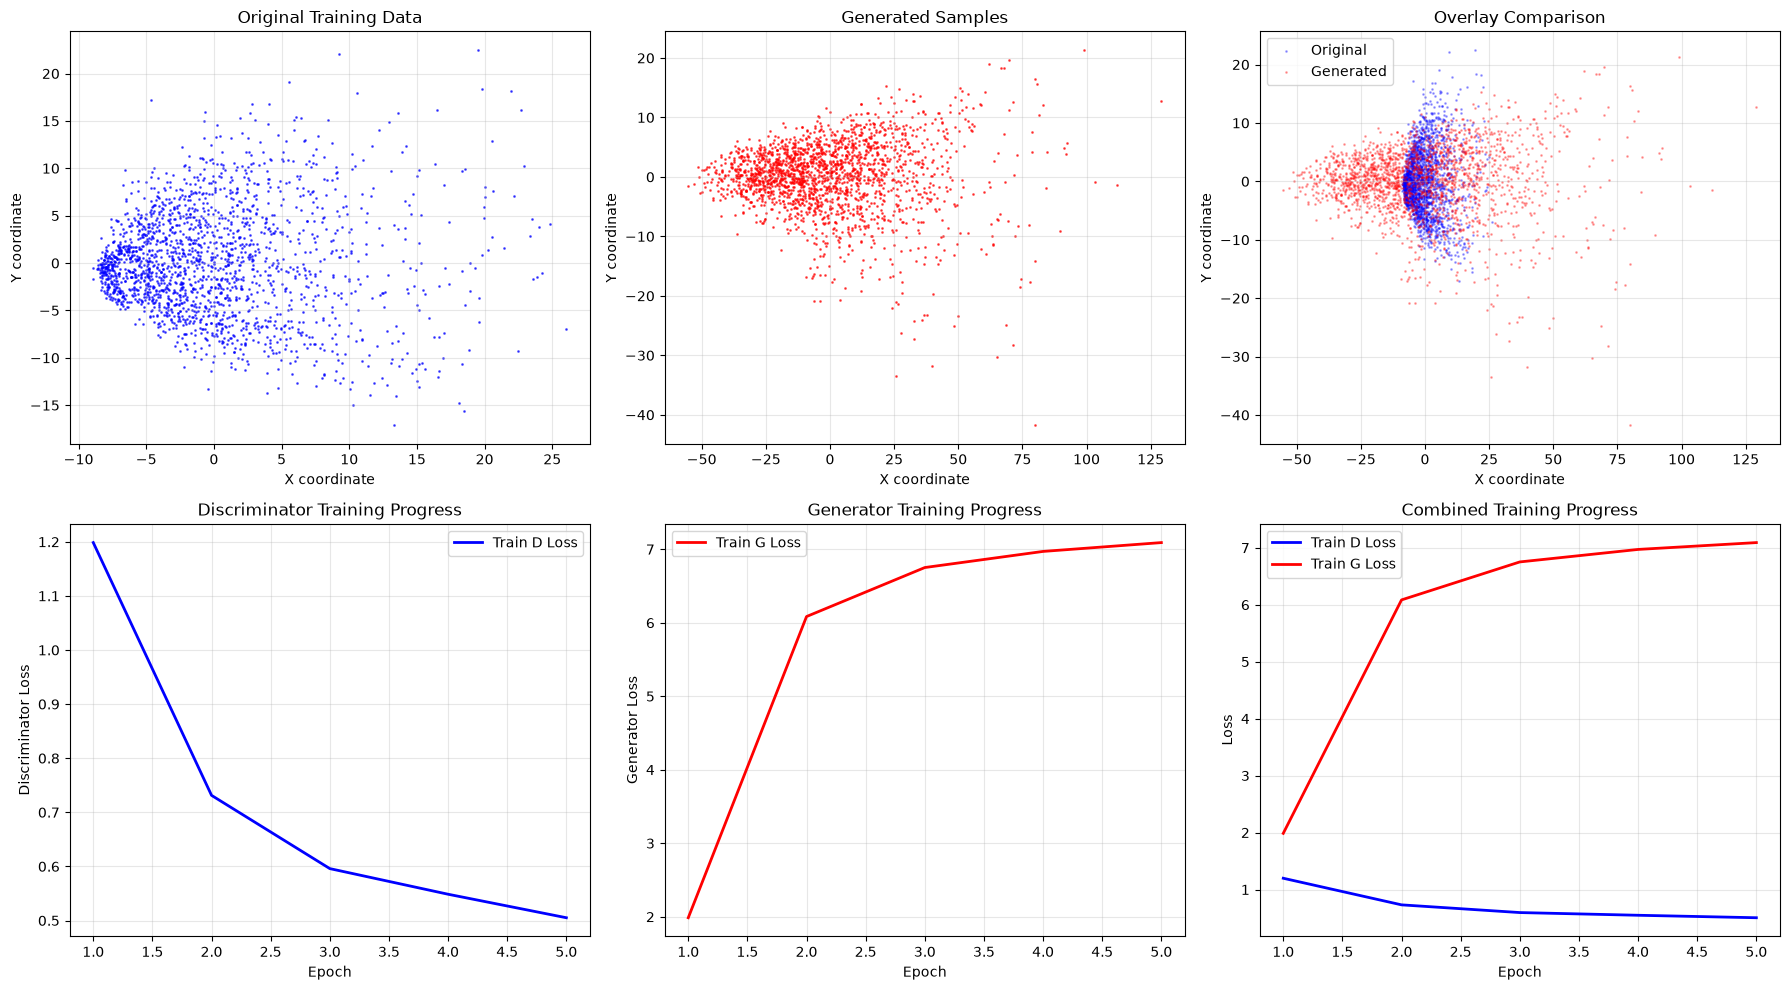

📈 Epoch 5 Summary:
   Train D Loss: 0.5051, Val D Loss: 0.1527
   Train G Loss: 7.0907, Val G Loss: 10.7582

📊 Epoch 6/100
----------------------------------------
Epoch: 6 [0/60000 (0%)]	D_loss: 0.139043	G_loss: 11.426828
Epoch: 6 [6400/60000 (11%)]	D_loss: 0.587686	G_loss: 6.891503
Epoch: 6 [12800/60000 (21%)]	D_loss: 0.245744	G_loss: 5.781100
Epoch: 6 [19200/60000 (32%)]	D_loss: 0.224248	G_loss: 4.247146
Epoch: 6 [25600/60000 (43%)]	D_loss: 0.110621	G_loss: 5.944589
Epoch: 6 [32000/60000 (53%)]	D_loss: 0.280201	G_loss: 4.824777
Epoch: 6 [38400/60000 (64%)]	D_loss: 0.449858	G_loss: 6.277216
Epoch: 6 [44800/60000 (75%)]	D_loss: 0.233158	G_loss: 4.718200
Epoch: 6 [51200/60000 (85%)]	D_loss: 0.209421	G_loss: 6.144927
Epoch: 6 [57600/60000 (96%)]	D_loss: 0.352375	G_loss: 4.733968
====> Epoch: 6 Train D_loss: 0.4277, Train G_loss: 6.2039
====> Epoch: 6 Val D_loss: 0.1981, Val G_loss: 4.8596
📈 Epoch 6 Summary:
   Train D Loss: 0.4277, Val D Loss: 0.1981
   Train G Loss: 6.2039, Val G Loss:

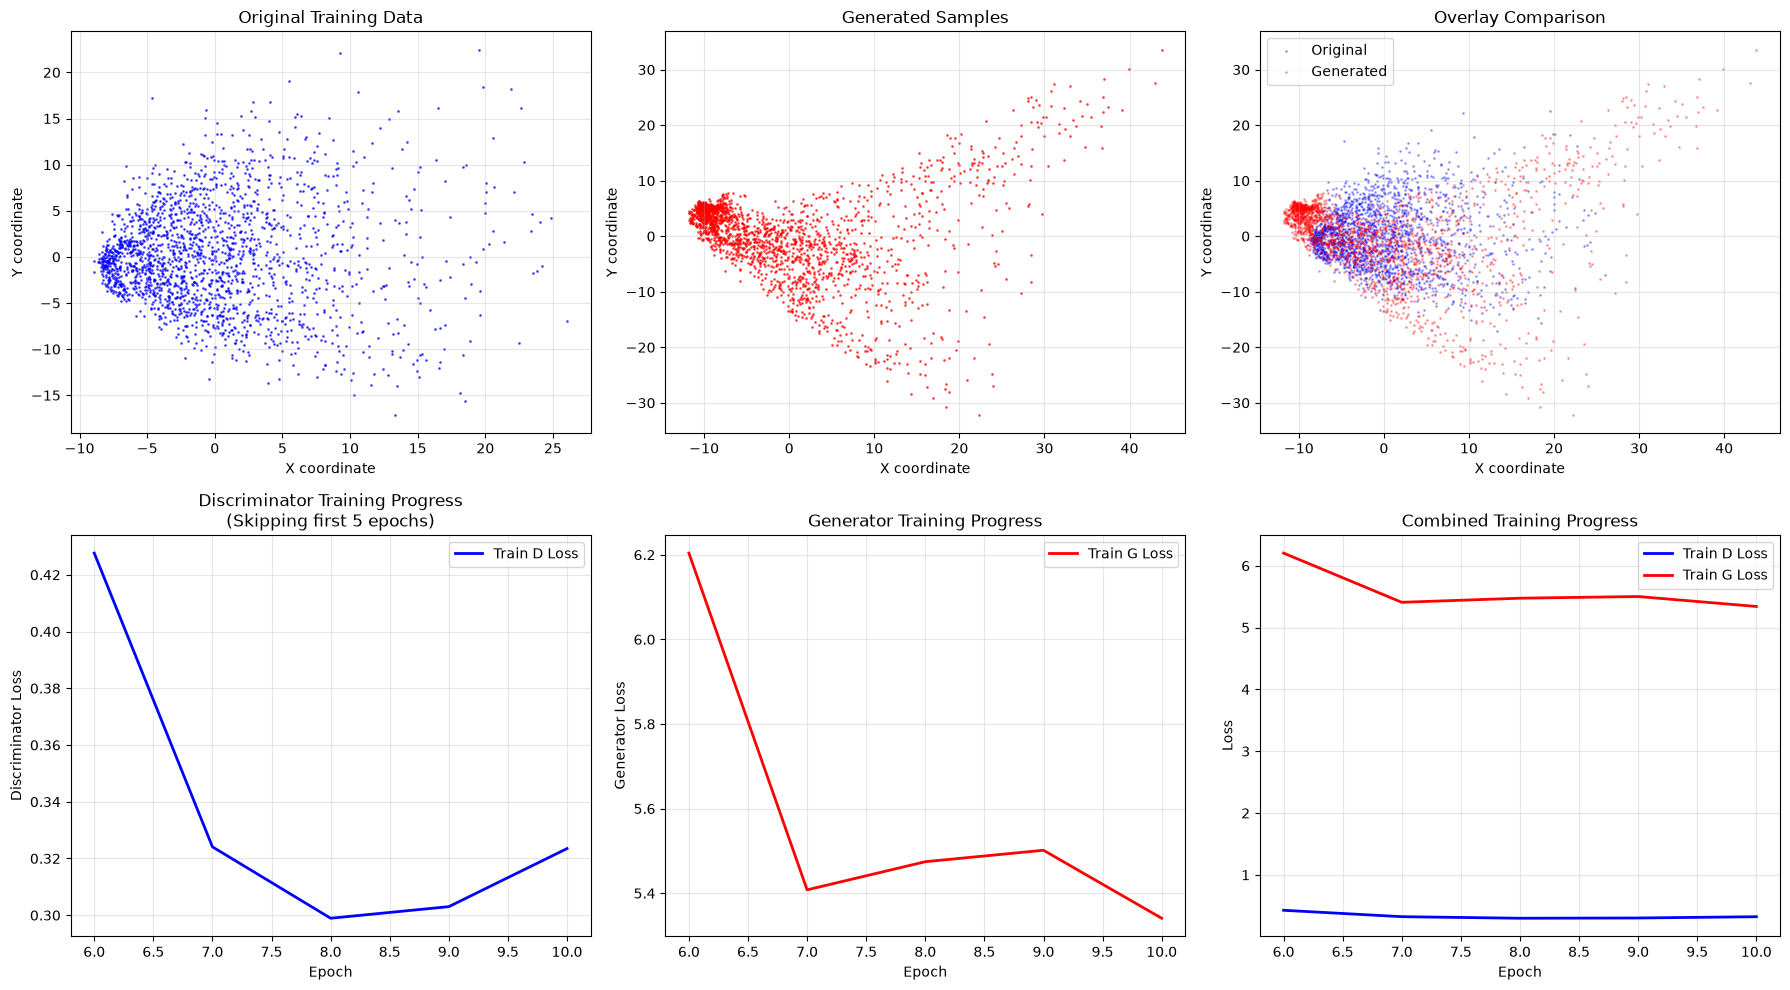

📈 Epoch 10 Summary:
   Train D Loss: 0.3235, Val D Loss: 2.3291
   Train G Loss: 5.3409, Val G Loss: 11.1527

📊 Epoch 11/100
----------------------------------------
Epoch: 11 [0/60000 (0%)]	D_loss: 2.219660	G_loss: 5.137933
Epoch: 11 [6400/60000 (11%)]	D_loss: 0.203193	G_loss: 3.299357
Epoch: 11 [12800/60000 (21%)]	D_loss: 0.204497	G_loss: 4.898962
Epoch: 11 [19200/60000 (32%)]	D_loss: 0.214952	G_loss: 2.578986
Epoch: 11 [25600/60000 (43%)]	D_loss: 0.260033	G_loss: 4.238297
Epoch: 11 [32000/60000 (53%)]	D_loss: 0.294953	G_loss: 3.962980
Epoch: 11 [38400/60000 (64%)]	D_loss: 0.187029	G_loss: 2.996511
Epoch: 11 [44800/60000 (75%)]	D_loss: 0.269743	G_loss: 4.496072
Epoch: 11 [51200/60000 (85%)]	D_loss: 0.531157	G_loss: 6.869012
Epoch: 11 [57600/60000 (96%)]	D_loss: 0.344664	G_loss: 6.365348
====> Epoch: 11 Train D_loss: 0.3418, Train G_loss: 4.9942
====> Epoch: 11 Val D_loss: 1.0615, Val G_loss: 4.6847
📈 Epoch 11 Summary:
   Train D Loss: 0.3418, Val D Loss: 1.0615
   Train G Loss: 4.994

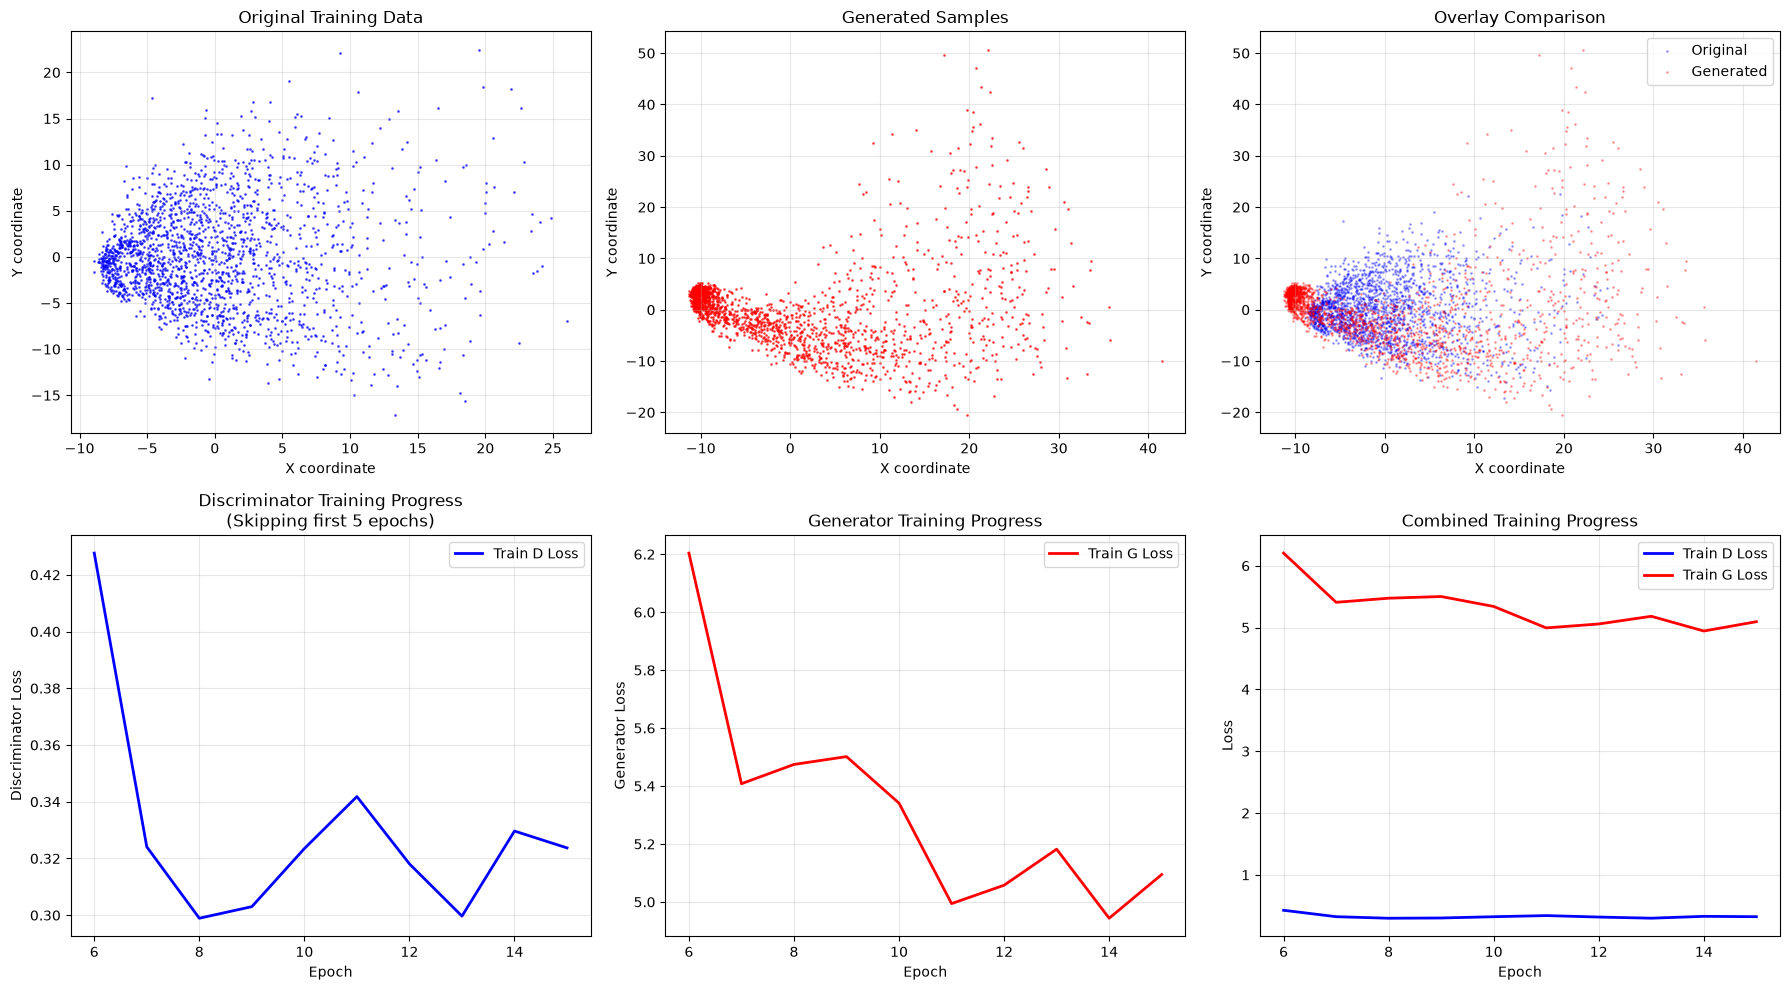

📈 Epoch 15 Summary:
   Train D Loss: 0.3237, Val D Loss: 0.2222
   Train G Loss: 5.0946, Val G Loss: 3.6222

📊 Epoch 16/100
----------------------------------------
Epoch: 16 [0/60000 (0%)]	D_loss: 0.239022	G_loss: 4.769274
Epoch: 16 [6400/60000 (11%)]	D_loss: 0.263224	G_loss: 3.846264
Epoch: 16 [12800/60000 (21%)]	D_loss: 0.332281	G_loss: 3.965533
Epoch: 16 [19200/60000 (32%)]	D_loss: 0.252684	G_loss: 4.208540
Epoch: 16 [25600/60000 (43%)]	D_loss: 0.118644	G_loss: 4.732512
Epoch: 16 [32000/60000 (53%)]	D_loss: 0.295355	G_loss: 5.965432
Epoch: 16 [38400/60000 (64%)]	D_loss: 0.182910	G_loss: 4.139682
Epoch: 16 [44800/60000 (75%)]	D_loss: 0.127497	G_loss: 5.081800
Epoch: 16 [51200/60000 (85%)]	D_loss: 0.376483	G_loss: 4.644279
Epoch: 16 [57600/60000 (96%)]	D_loss: 0.189804	G_loss: 5.535757
====> Epoch: 16 Train D_loss: 0.2871, Train G_loss: 5.2477
====> Epoch: 16 Val D_loss: 0.2376, Val G_loss: 4.7459
📈 Epoch 16 Summary:
   Train D Loss: 0.2871, Val D Loss: 0.2376
   Train G Loss: 5.2477

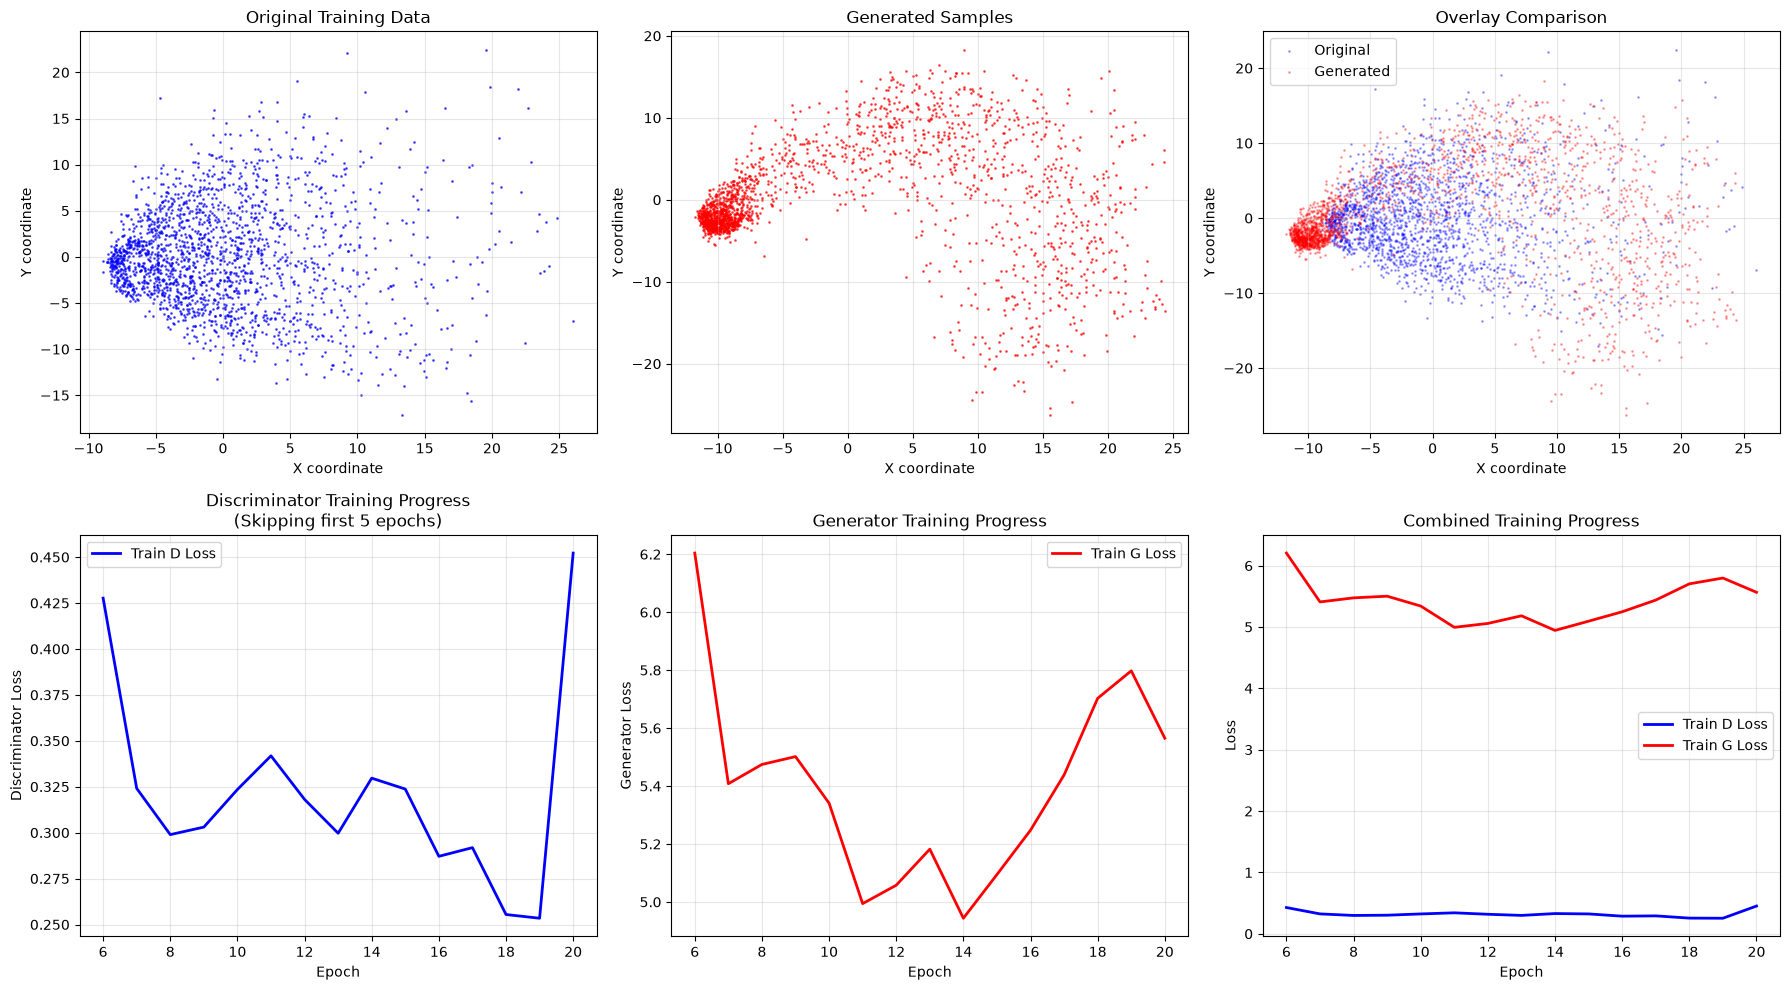

📈 Epoch 20 Summary:
   Train D Loss: 0.4522, Val D Loss: 0.3363
   Train G Loss: 5.5650, Val G Loss: 5.0938

📊 Epoch 21/100
----------------------------------------
Epoch: 21 [0/60000 (0%)]	D_loss: 0.351348	G_loss: 3.998330
Epoch: 21 [6400/60000 (11%)]	D_loss: 0.241547	G_loss: 2.826174
Epoch: 21 [12800/60000 (21%)]	D_loss: 0.268633	G_loss: 4.481630
Epoch: 21 [19200/60000 (32%)]	D_loss: 0.208627	G_loss: 4.857586
Epoch: 21 [25600/60000 (43%)]	D_loss: 0.233591	G_loss: 5.805162
Epoch: 21 [32000/60000 (53%)]	D_loss: 0.203805	G_loss: 4.967126
Epoch: 21 [38400/60000 (64%)]	D_loss: 0.070542	G_loss: 4.853492
Epoch: 21 [44800/60000 (75%)]	D_loss: 0.227227	G_loss: 7.299300
Epoch: 21 [51200/60000 (85%)]	D_loss: 0.277157	G_loss: 5.715004
Epoch: 21 [57600/60000 (96%)]	D_loss: 0.166840	G_loss: 4.101388
====> Epoch: 21 Train D_loss: 0.2582, Train G_loss: 5.3141
====> Epoch: 21 Val D_loss: 0.2308, Val G_loss: 3.2345
📈 Epoch 21 Summary:
   Train D Loss: 0.2582, Val D Loss: 0.2308
   Train G Loss: 5.3141

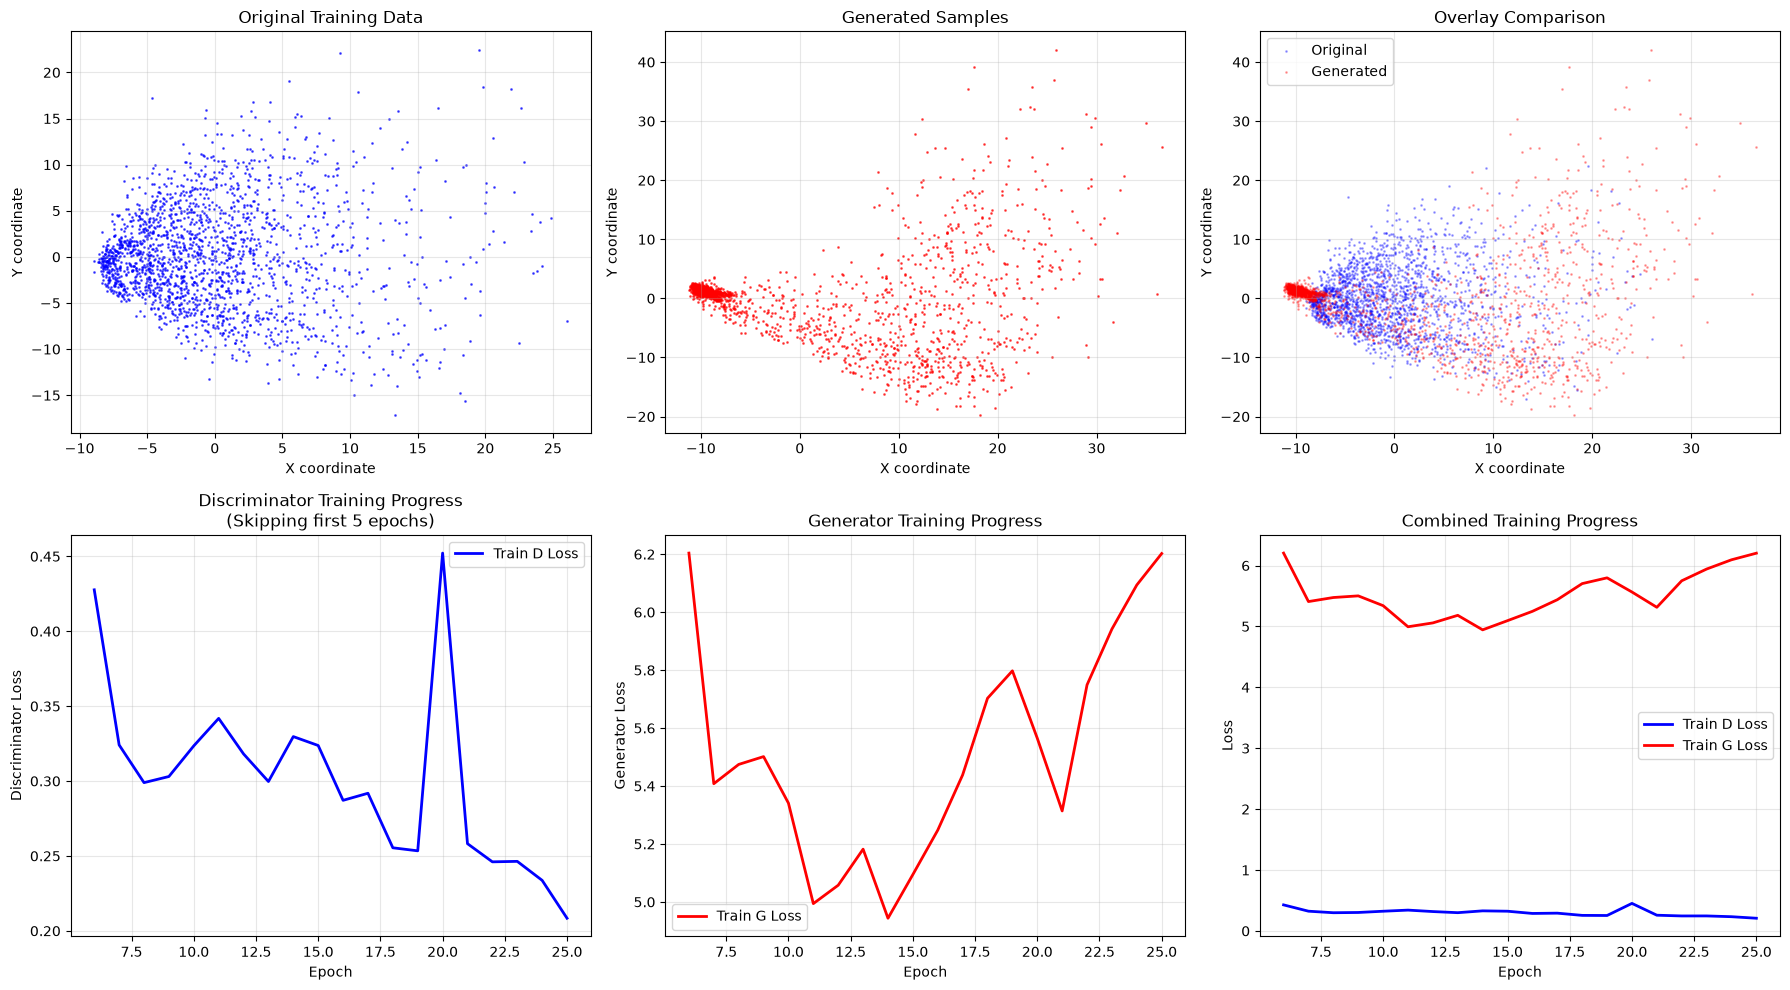

📈 Epoch 25 Summary:
   Train D Loss: 0.2084, Val D Loss: 0.3627
   Train G Loss: 6.2024, Val G Loss: 4.3034

📊 Epoch 26/100
----------------------------------------
Epoch: 26 [0/60000 (0%)]	D_loss: 0.275060	G_loss: 7.297389
Epoch: 26 [6400/60000 (11%)]	D_loss: 0.131724	G_loss: 7.309012
Epoch: 26 [12800/60000 (21%)]	D_loss: 0.282104	G_loss: 5.298457
Epoch: 26 [19200/60000 (32%)]	D_loss: 0.136077	G_loss: 4.172309
Epoch: 26 [25600/60000 (43%)]	D_loss: 0.250895	G_loss: 7.764982
Epoch: 26 [32000/60000 (53%)]	D_loss: 0.237241	G_loss: 4.557378
Epoch: 26 [38400/60000 (64%)]	D_loss: 0.143619	G_loss: 4.704822
Epoch: 26 [44800/60000 (75%)]	D_loss: 0.199646	G_loss: 5.678466
Epoch: 26 [51200/60000 (85%)]	D_loss: 0.413569	G_loss: 7.948890
Epoch: 26 [57600/60000 (96%)]	D_loss: 0.181264	G_loss: 6.230540
====> Epoch: 26 Train D_loss: 0.2294, Train G_loss: 5.9932
====> Epoch: 26 Val D_loss: 0.3460, Val G_loss: 6.7289
📈 Epoch 26 Summary:
   Train D Loss: 0.2294, Val D Loss: 0.3460
   Train G Loss: 5.9932

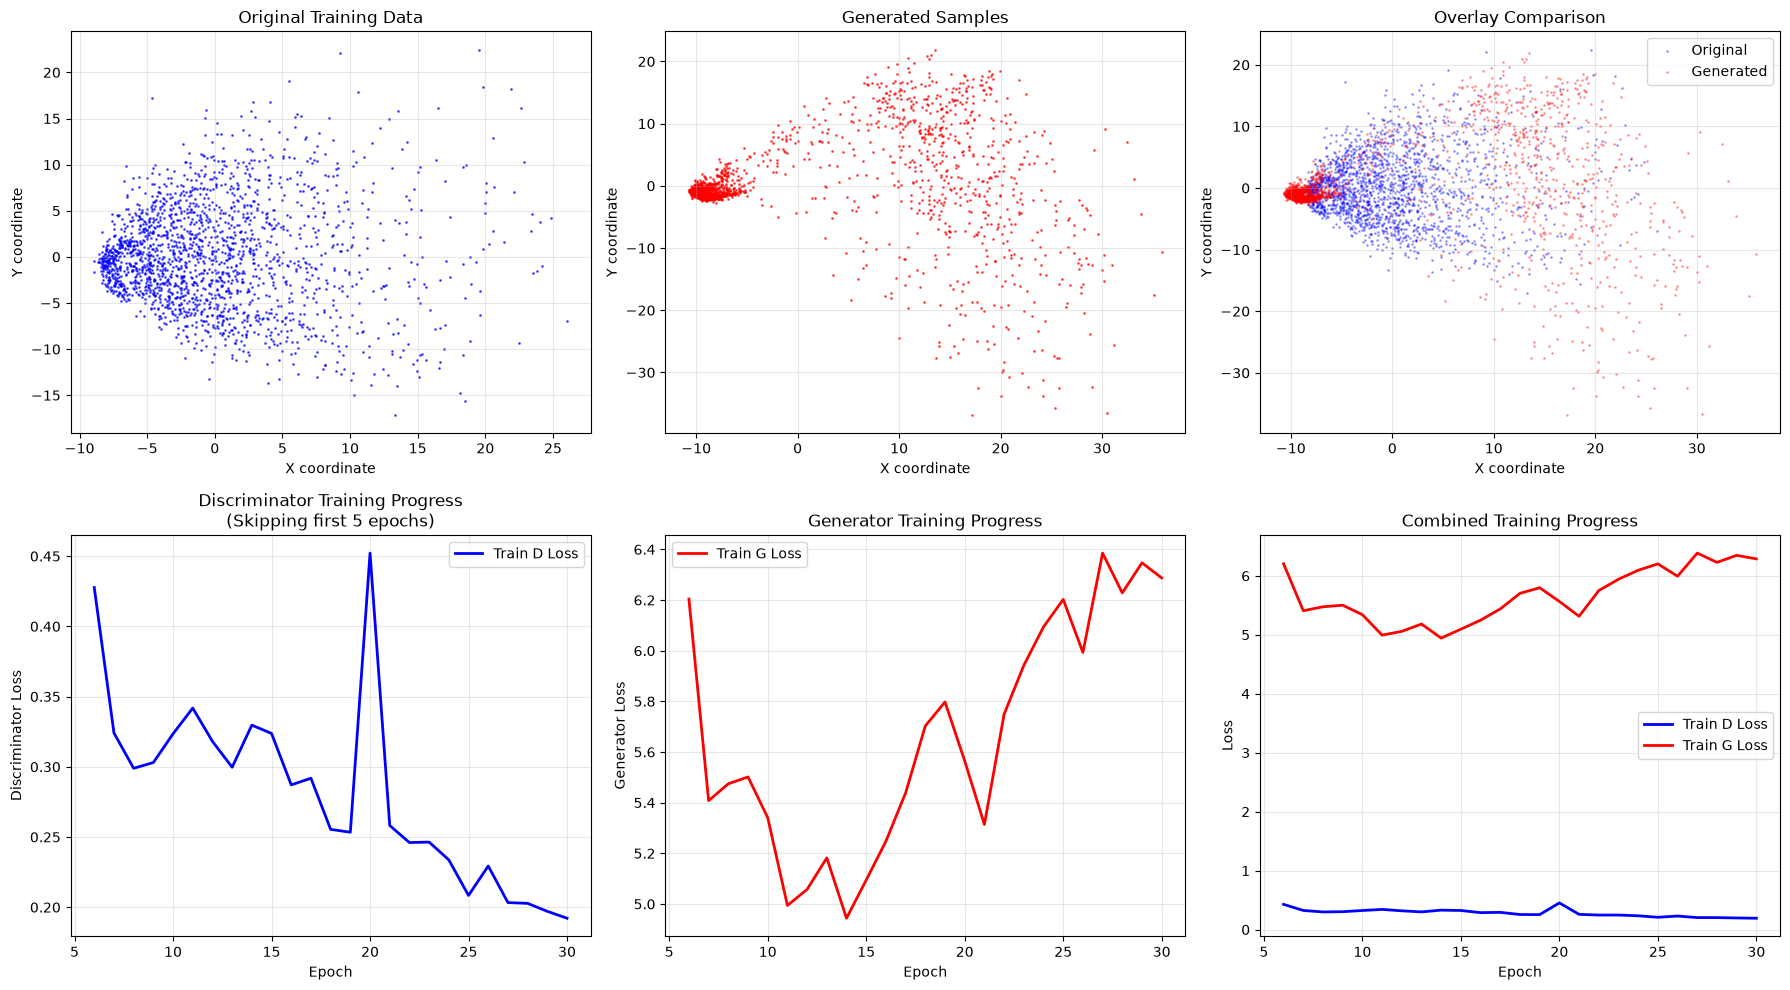

📈 Epoch 30 Summary:
   Train D Loss: 0.1922, Val D Loss: 0.1667
   Train G Loss: 6.2871, Val G Loss: 4.6772

📊 Epoch 31/100
----------------------------------------
Epoch: 31 [0/60000 (0%)]	D_loss: 0.088717	G_loss: 5.072389
Epoch: 31 [6400/60000 (11%)]	D_loss: 0.133725	G_loss: 4.188287
Epoch: 31 [12800/60000 (21%)]	D_loss: 0.144617	G_loss: 6.087177
Epoch: 31 [19200/60000 (32%)]	D_loss: 0.417114	G_loss: 6.727752
Epoch: 31 [25600/60000 (43%)]	D_loss: 0.180307	G_loss: 4.667281
Epoch: 31 [32000/60000 (53%)]	D_loss: 0.132026	G_loss: 7.399764
Epoch: 31 [38400/60000 (64%)]	D_loss: 0.046029	G_loss: 5.606576
Epoch: 31 [44800/60000 (75%)]	D_loss: 0.225414	G_loss: 6.240682
Epoch: 31 [51200/60000 (85%)]	D_loss: 0.252384	G_loss: 4.243477
Epoch: 31 [57600/60000 (96%)]	D_loss: 0.239605	G_loss: 4.894088
====> Epoch: 31 Train D_loss: 0.2014, Train G_loss: 6.3277
====> Epoch: 31 Val D_loss: 0.1766, Val G_loss: 6.1427
📈 Epoch 31 Summary:
   Train D Loss: 0.2014, Val D Loss: 0.1766
   Train G Loss: 6.3277

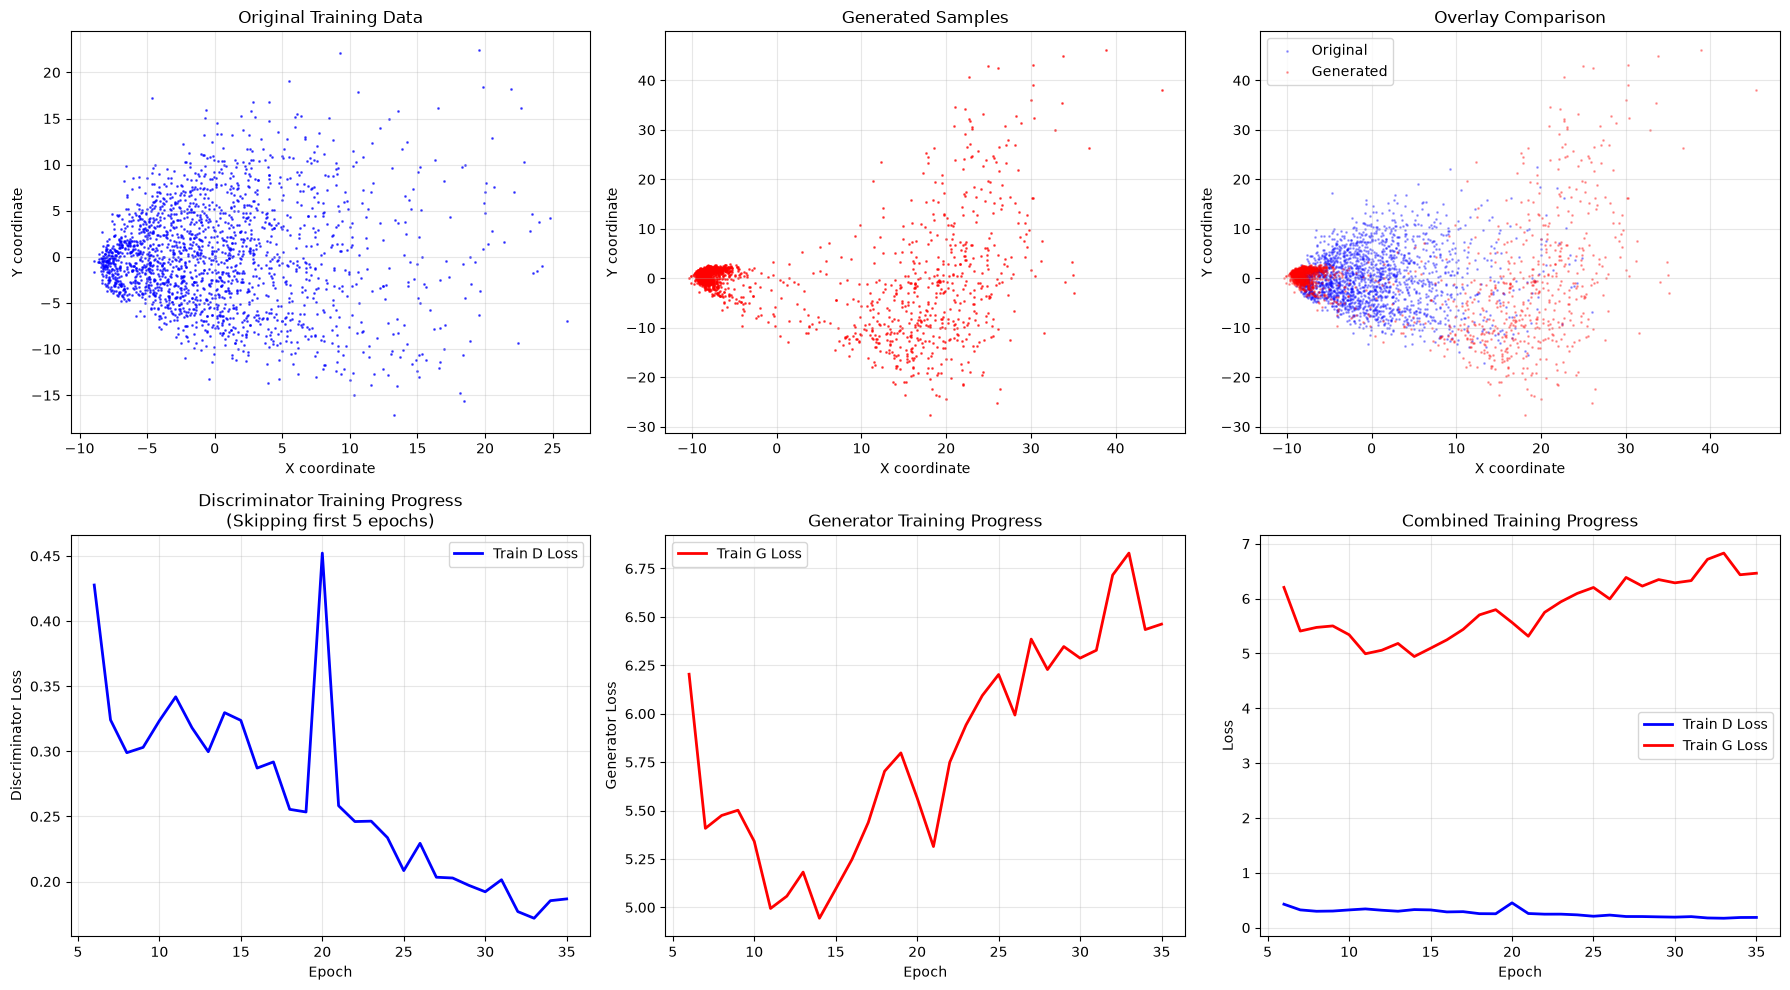

📈 Epoch 35 Summary:
   Train D Loss: 0.1867, Val D Loss: 0.1717
   Train G Loss: 6.4626, Val G Loss: 5.4632

📊 Epoch 36/100
----------------------------------------
Epoch: 36 [0/60000 (0%)]	D_loss: 0.121122	G_loss: 6.478382
Epoch: 36 [6400/60000 (11%)]	D_loss: 0.083380	G_loss: 6.595753
Epoch: 36 [12800/60000 (21%)]	D_loss: 0.050943	G_loss: 7.921815
Epoch: 36 [19200/60000 (32%)]	D_loss: 0.219999	G_loss: 5.514303
Epoch: 36 [25600/60000 (43%)]	D_loss: 0.215093	G_loss: 4.467752
Epoch: 36 [32000/60000 (53%)]	D_loss: 0.047543	G_loss: 7.562036
Epoch: 36 [38400/60000 (64%)]	D_loss: 0.193063	G_loss: 4.902994
Epoch: 36 [44800/60000 (75%)]	D_loss: 0.129844	G_loss: 6.322712
Epoch: 36 [51200/60000 (85%)]	D_loss: 0.148583	G_loss: 10.964809
Epoch: 36 [57600/60000 (96%)]	D_loss: 0.162621	G_loss: 8.708418
====> Epoch: 36 Train D_loss: 0.1641, Train G_loss: 6.8668
====> Epoch: 36 Val D_loss: 0.2570, Val G_loss: 6.3518
📈 Epoch 36 Summary:
   Train D Loss: 0.1641, Val D Loss: 0.2570
   Train G Loss: 6.866

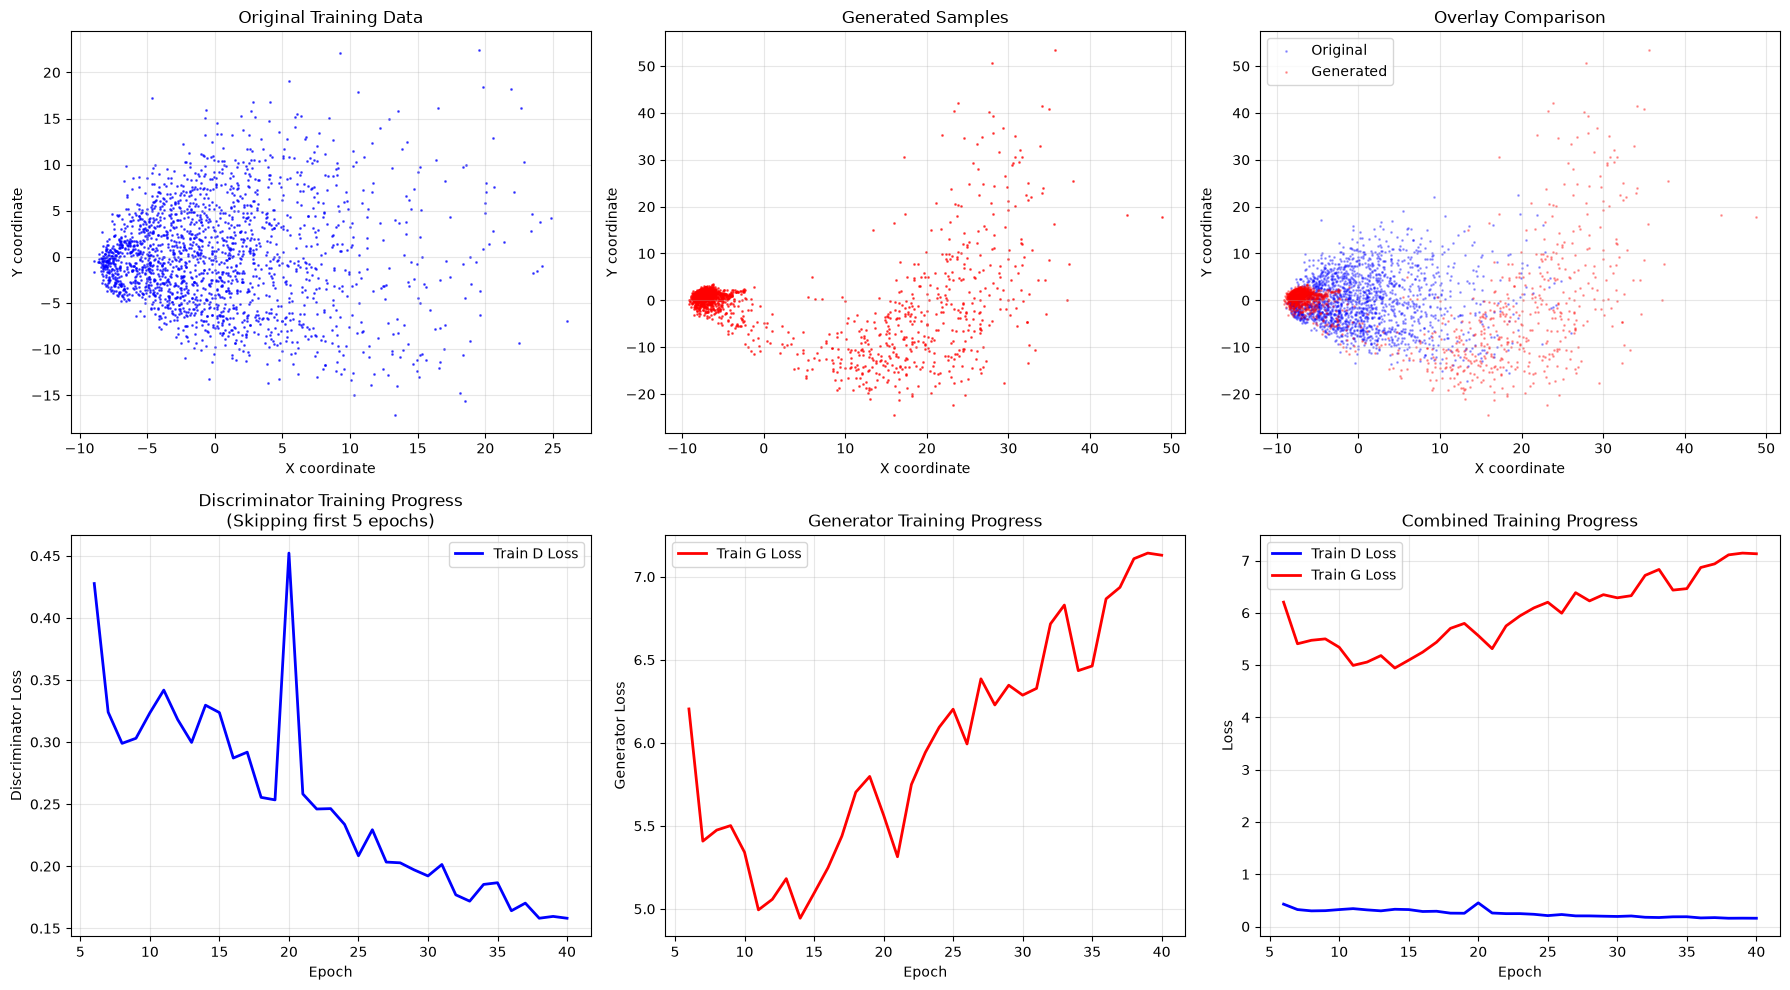

📈 Epoch 40 Summary:
   Train D Loss: 0.1581, Val D Loss: 0.1746
   Train G Loss: 7.1297, Val G Loss: 5.1425

📊 Epoch 41/100
----------------------------------------
Epoch: 41 [0/60000 (0%)]	D_loss: 0.175680	G_loss: 5.957287
Epoch: 41 [6400/60000 (11%)]	D_loss: 0.091983	G_loss: 5.954610
Epoch: 41 [12800/60000 (21%)]	D_loss: 0.059643	G_loss: 6.516870
Epoch: 41 [19200/60000 (32%)]	D_loss: 0.156981	G_loss: 9.053164
Epoch: 41 [25600/60000 (43%)]	D_loss: 0.223743	G_loss: 6.561891
Epoch: 41 [32000/60000 (53%)]	D_loss: 0.114021	G_loss: 7.044335
Epoch: 41 [38400/60000 (64%)]	D_loss: 0.124734	G_loss: 6.221443
Epoch: 41 [44800/60000 (75%)]	D_loss: 0.197193	G_loss: 6.710961
Epoch: 41 [51200/60000 (85%)]	D_loss: 0.111904	G_loss: 6.745855
Epoch: 41 [57600/60000 (96%)]	D_loss: 0.077019	G_loss: 9.437748
====> Epoch: 41 Train D_loss: 0.1473, Train G_loss: 7.5436
====> Epoch: 41 Val D_loss: 0.1456, Val G_loss: 8.3506
📈 Epoch 41 Summary:
   Train D Loss: 0.1473, Val D Loss: 0.1456
   Train G Loss: 7.5436

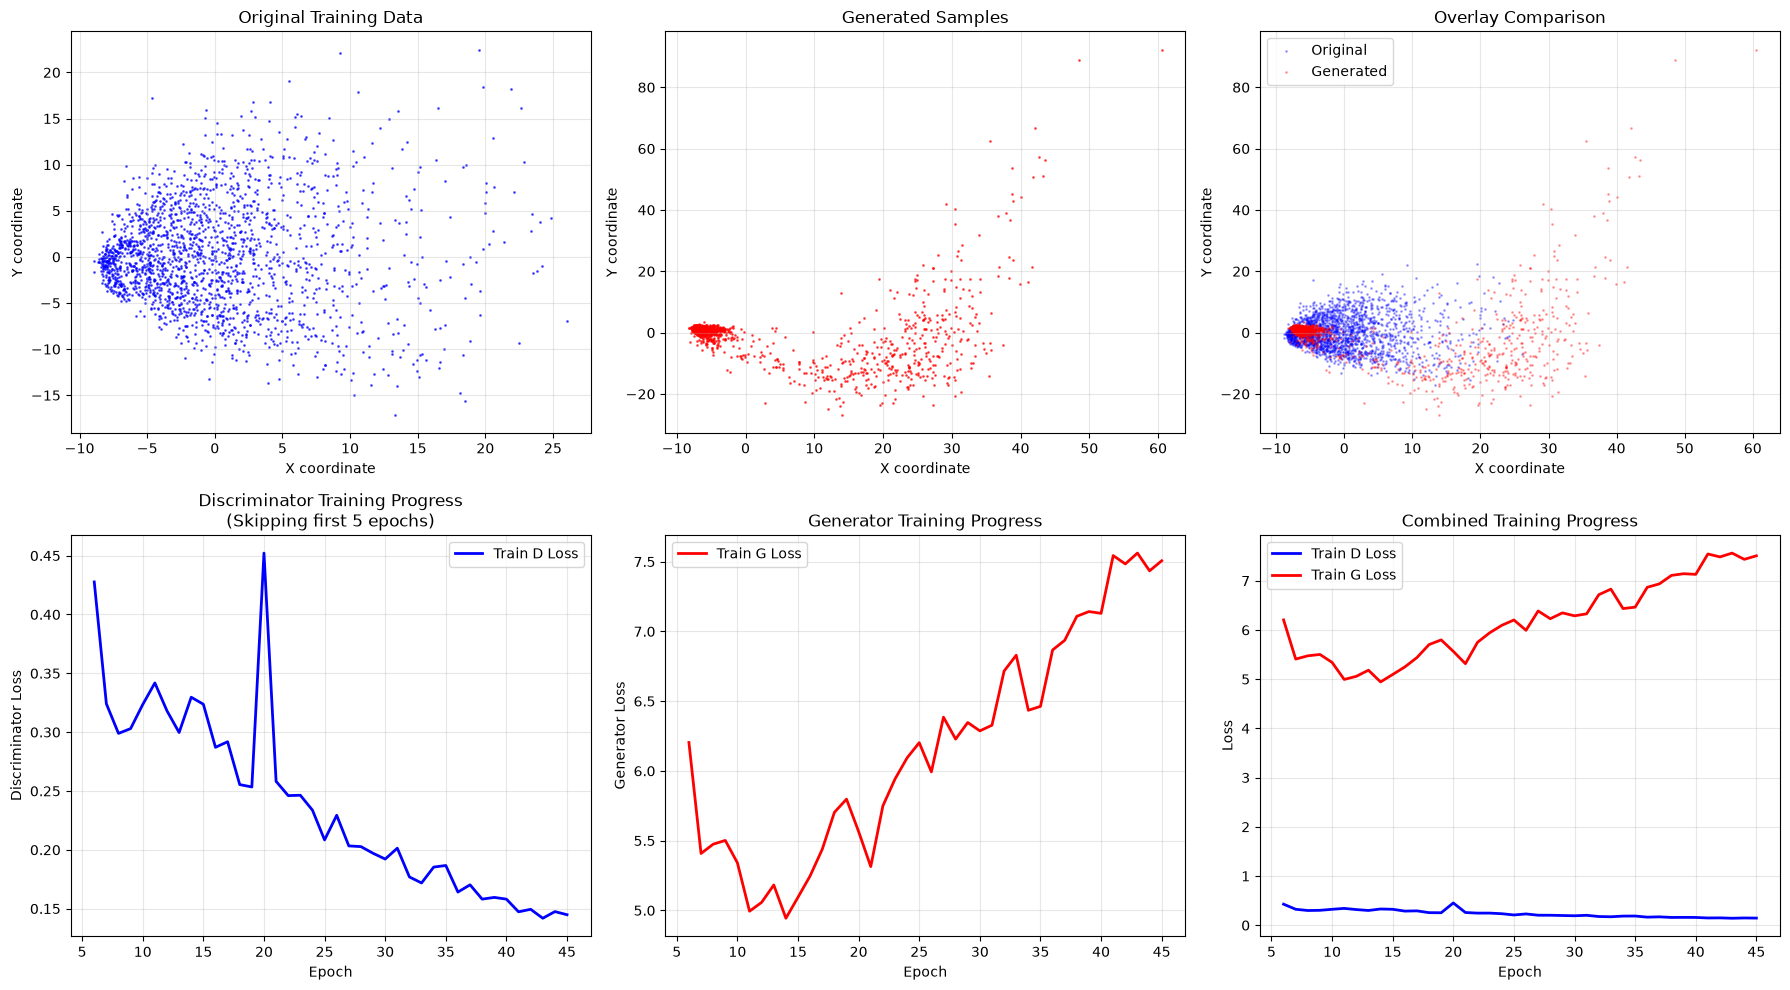

📈 Epoch 45 Summary:
   Train D Loss: 0.1448, Val D Loss: 0.1908
   Train G Loss: 7.5065, Val G Loss: 5.9050

📊 Epoch 46/100
----------------------------------------
Epoch: 46 [0/60000 (0%)]	D_loss: 0.115001	G_loss: 5.579787
Epoch: 46 [6400/60000 (11%)]	D_loss: 0.144034	G_loss: 11.537804
Epoch: 46 [12800/60000 (21%)]	D_loss: 0.166849	G_loss: 8.667917
Epoch: 46 [19200/60000 (32%)]	D_loss: 0.167488	G_loss: 9.712540
Epoch: 46 [25600/60000 (43%)]	D_loss: 0.120479	G_loss: 7.081364
Epoch: 46 [32000/60000 (53%)]	D_loss: 0.084691	G_loss: 5.984007
Epoch: 46 [38400/60000 (64%)]	D_loss: 0.125413	G_loss: 7.752916
Epoch: 46 [44800/60000 (75%)]	D_loss: 0.308734	G_loss: 9.765202
Epoch: 46 [51200/60000 (85%)]	D_loss: 0.111979	G_loss: 5.700138
Epoch: 46 [57600/60000 (96%)]	D_loss: 0.076965	G_loss: 6.362572
====> Epoch: 46 Train D_loss: 0.1366, Train G_loss: 7.6993
====> Epoch: 46 Val D_loss: 0.1287, Val G_loss: 6.0892
📈 Epoch 46 Summary:
   Train D Loss: 0.1366, Val D Loss: 0.1287
   Train G Loss: 7.699

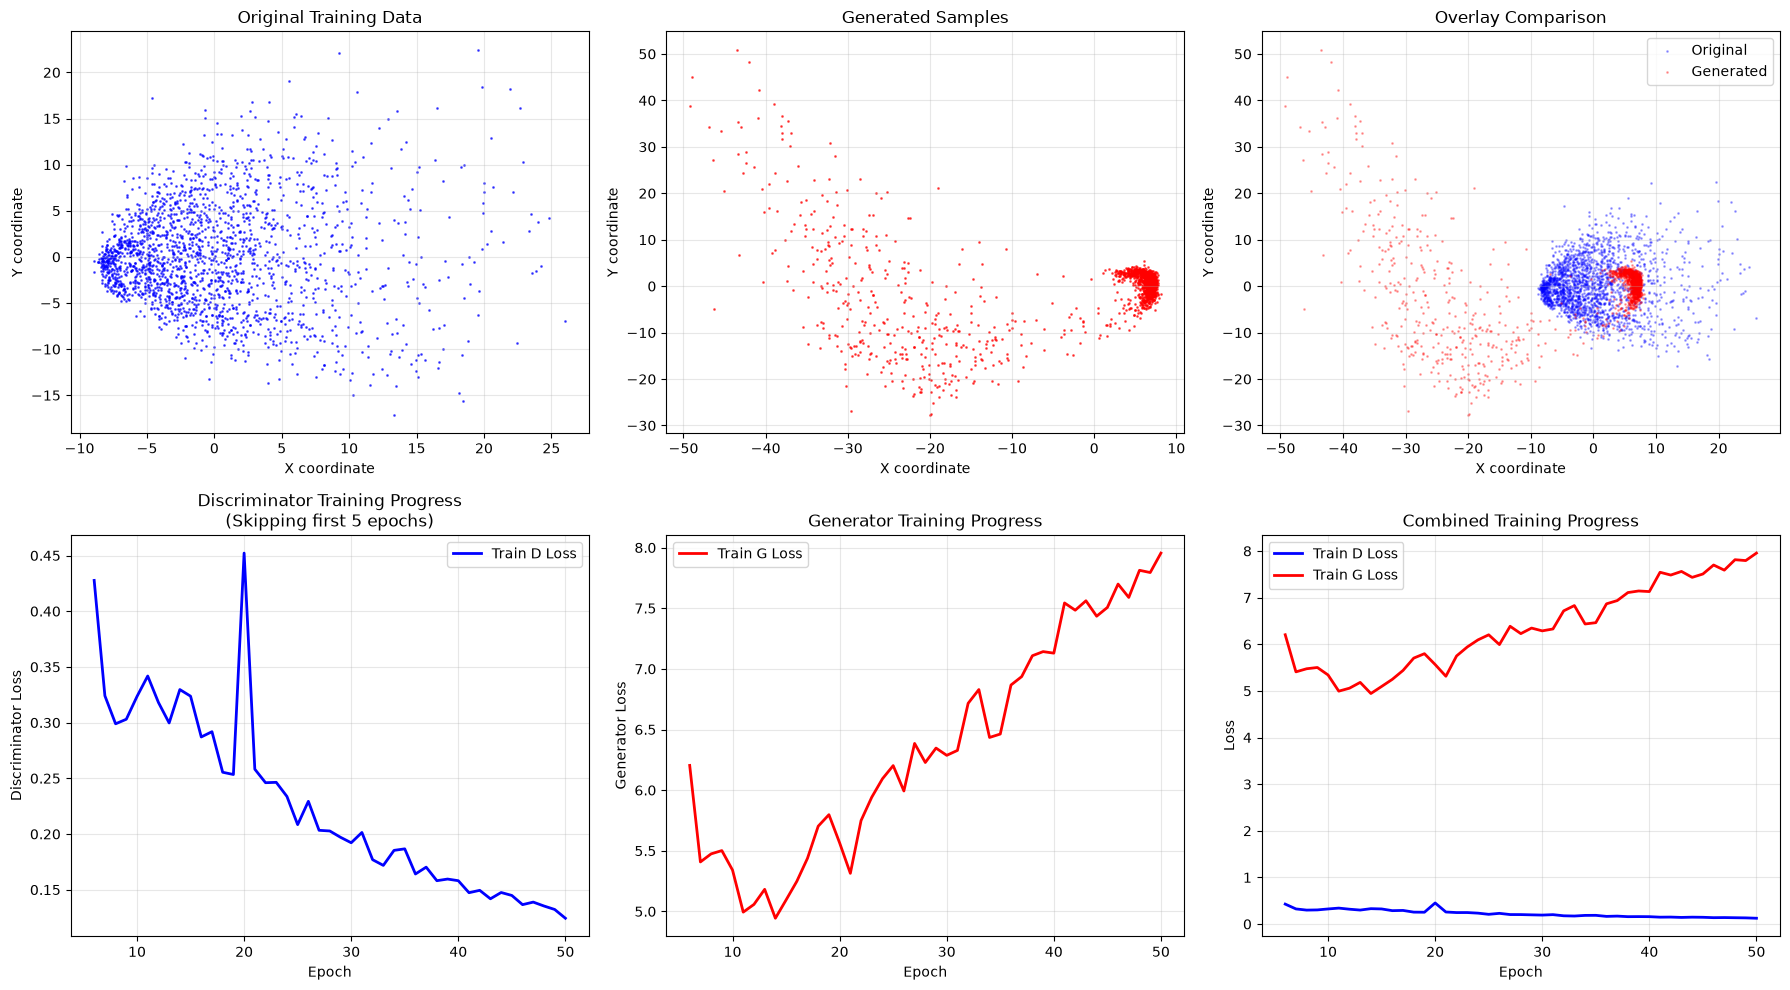

📈 Epoch 50 Summary:
   Train D Loss: 0.1244, Val D Loss: 0.1199
   Train G Loss: 7.9547, Val G Loss: 8.0604

📊 Epoch 51/100
----------------------------------------
Epoch: 51 [0/60000 (0%)]	D_loss: 0.062465	G_loss: 7.367237
Epoch: 51 [6400/60000 (11%)]	D_loss: 0.045068	G_loss: 8.646725
Epoch: 51 [12800/60000 (21%)]	D_loss: 0.149990	G_loss: 9.914991
Epoch: 51 [19200/60000 (32%)]	D_loss: 0.065564	G_loss: 10.481170
Epoch: 51 [25600/60000 (43%)]	D_loss: 0.178915	G_loss: 8.459539
Epoch: 51 [32000/60000 (53%)]	D_loss: 0.044213	G_loss: 8.041283
Epoch: 51 [38400/60000 (64%)]	D_loss: 0.108175	G_loss: 7.786144
Epoch: 51 [44800/60000 (75%)]	D_loss: 0.201292	G_loss: 5.603021
Epoch: 51 [51200/60000 (85%)]	D_loss: 0.117102	G_loss: 8.369694
Epoch: 51 [57600/60000 (96%)]	D_loss: 0.118640	G_loss: 8.199621
====> Epoch: 51 Train D_loss: 0.1181, Train G_loss: 8.4726
====> Epoch: 51 Val D_loss: 0.2091, Val G_loss: 4.1896
📈 Epoch 51 Summary:
   Train D Loss: 0.1181, Val D Loss: 0.2091
   Train G Loss: 8.472

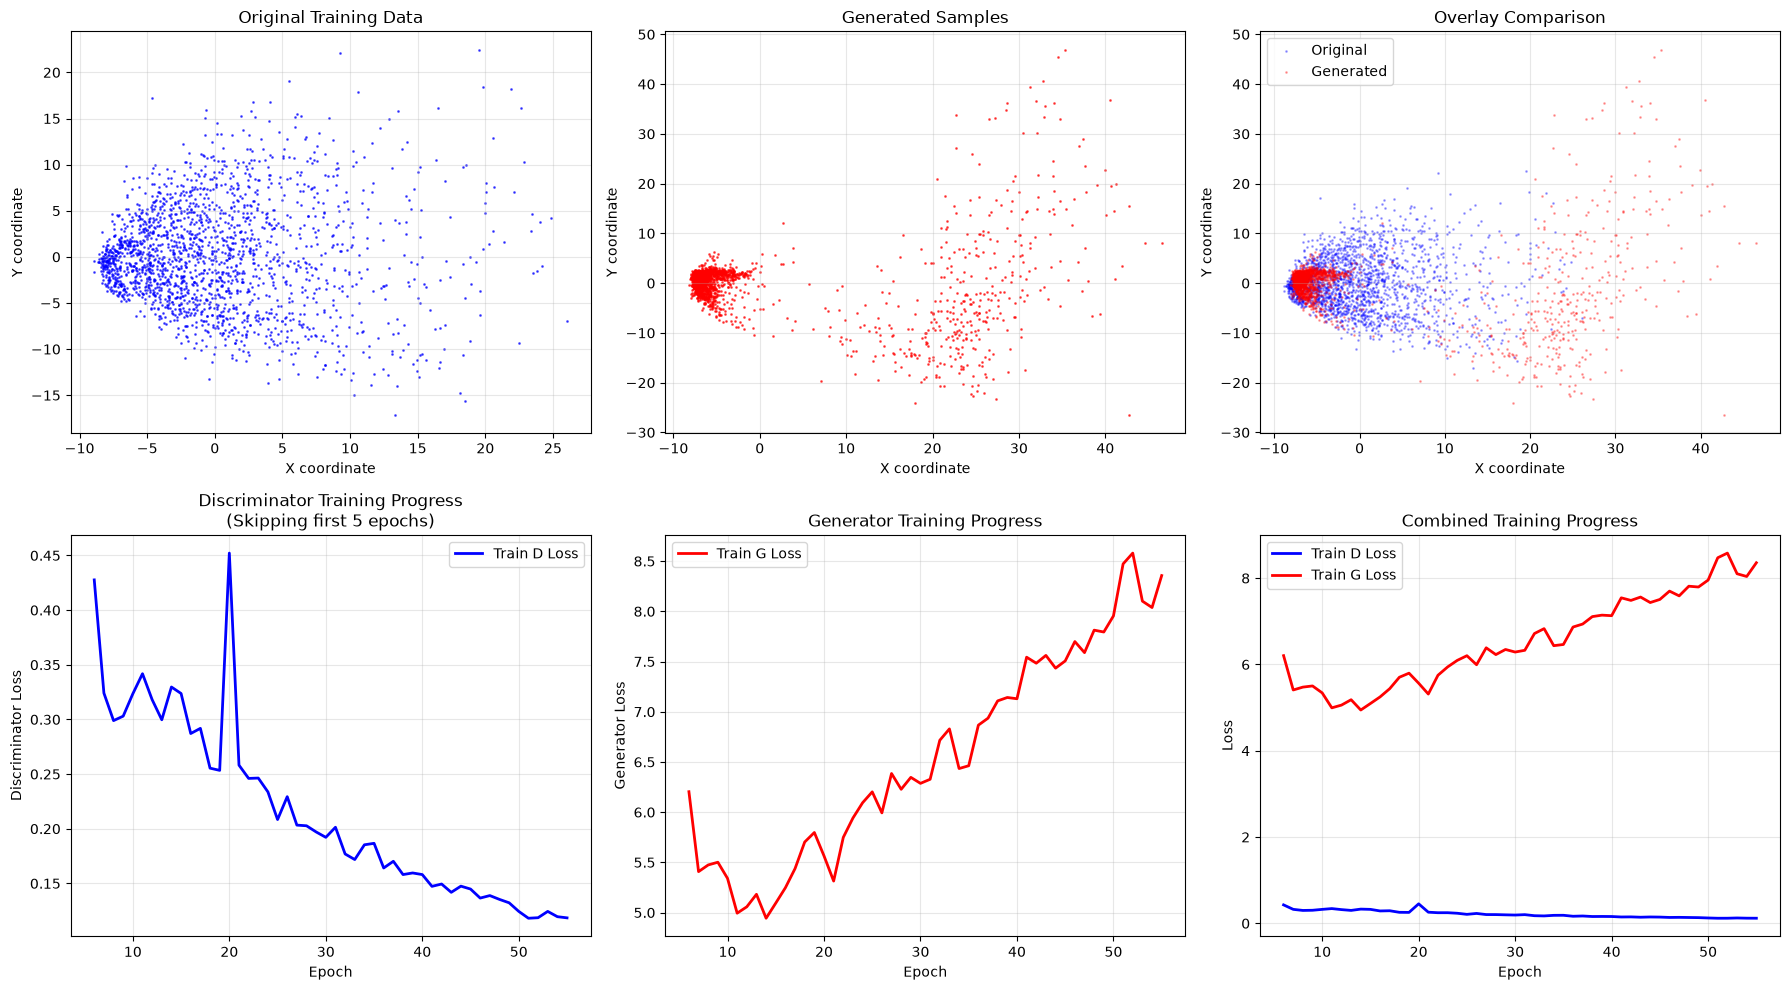

📈 Epoch 55 Summary:
   Train D Loss: 0.1185, Val D Loss: 0.1233
   Train G Loss: 8.3567, Val G Loss: 7.0068

📊 Epoch 56/100
----------------------------------------
Epoch: 56 [0/60000 (0%)]	D_loss: 0.041990	G_loss: 7.979488
Epoch: 56 [6400/60000 (11%)]	D_loss: 0.153018	G_loss: 7.099874
Epoch: 56 [12800/60000 (21%)]	D_loss: 0.092726	G_loss: 6.905622
Epoch: 56 [19200/60000 (32%)]	D_loss: 0.124949	G_loss: 7.552286
Epoch: 56 [25600/60000 (43%)]	D_loss: 0.114243	G_loss: 5.412875
Epoch: 56 [32000/60000 (53%)]	D_loss: 0.233583	G_loss: 6.858569
Epoch: 56 [38400/60000 (64%)]	D_loss: 0.074528	G_loss: 8.868042
Epoch: 56 [44800/60000 (75%)]	D_loss: 0.222621	G_loss: 7.464735
Epoch: 56 [51200/60000 (85%)]	D_loss: 0.042107	G_loss: 10.694111
Epoch: 56 [57600/60000 (96%)]	D_loss: 0.085738	G_loss: 5.795576
====> Epoch: 56 Train D_loss: 0.1143, Train G_loss: 8.3607
====> Epoch: 56 Val D_loss: 0.1721, Val G_loss: 6.3343
📈 Epoch 56 Summary:
   Train D Loss: 0.1143, Val D Loss: 0.1721
   Train G Loss: 8.360

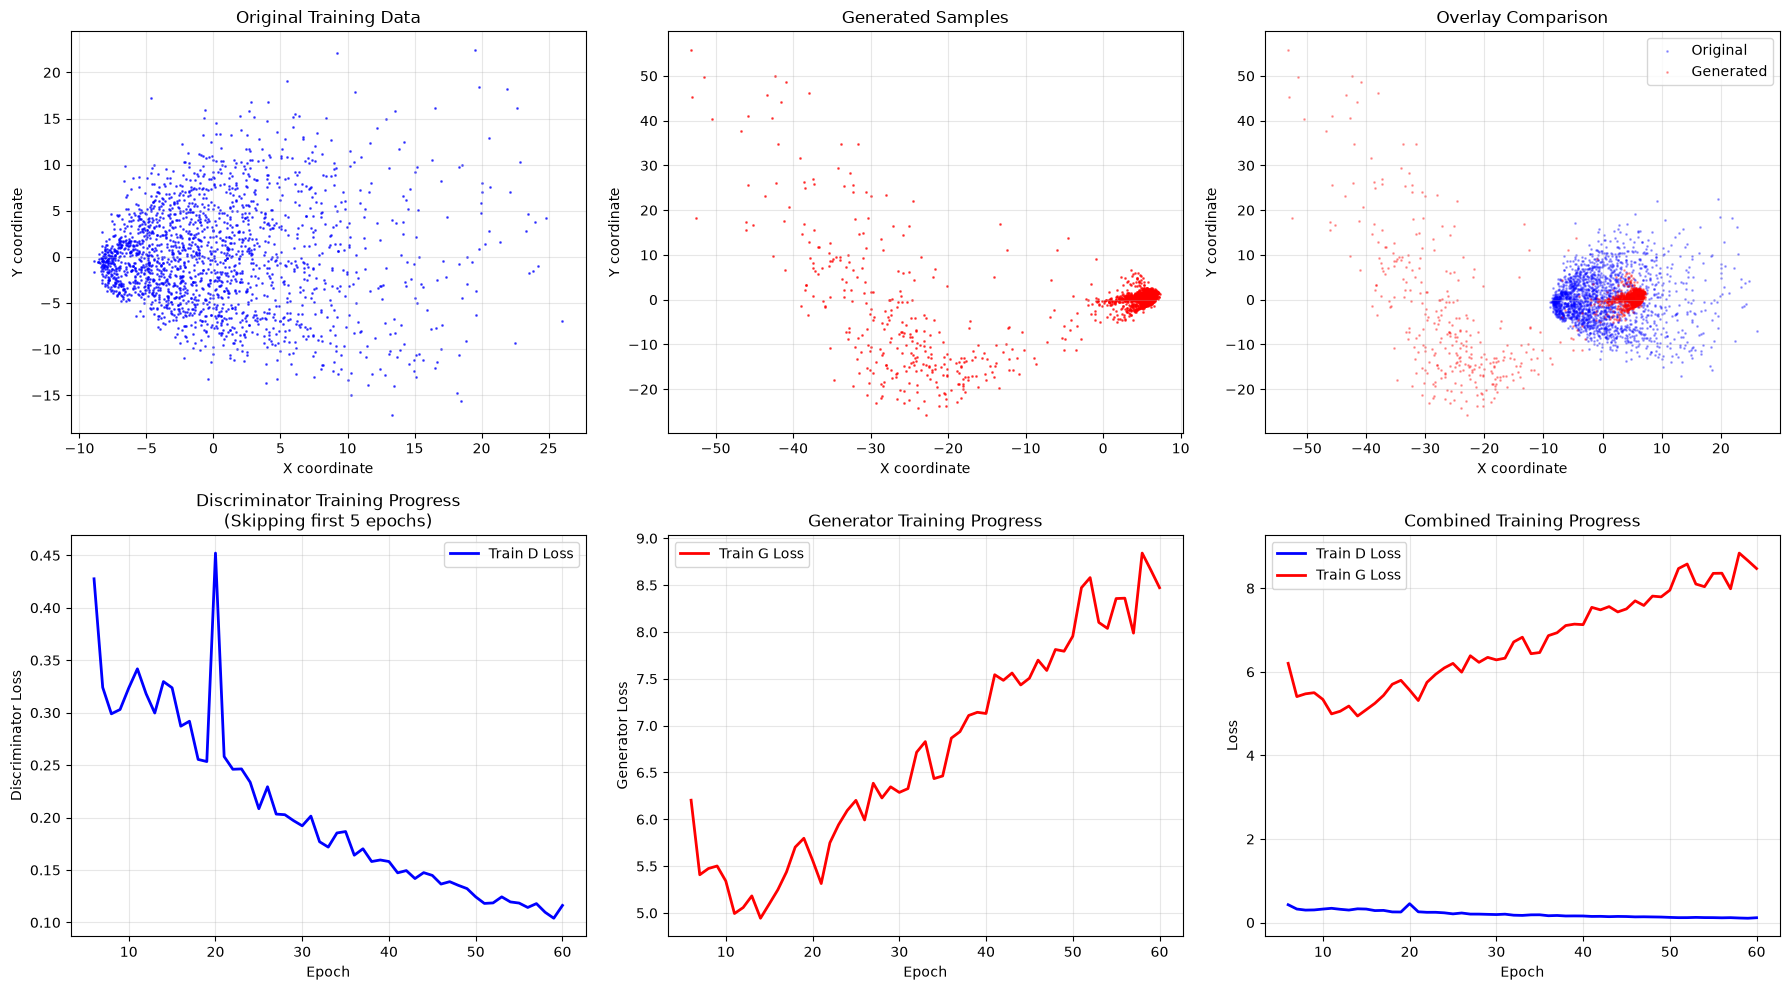

📈 Epoch 60 Summary:
   Train D Loss: 0.1162, Val D Loss: 0.1160
   Train G Loss: 8.4726, Val G Loss: 7.3163

📊 Epoch 61/100
----------------------------------------
Epoch: 61 [0/60000 (0%)]	D_loss: 0.083404	G_loss: 8.766225
Epoch: 61 [6400/60000 (11%)]	D_loss: 0.261904	G_loss: 6.941936
Epoch: 61 [12800/60000 (21%)]	D_loss: 0.040838	G_loss: 12.590153
Epoch: 61 [19200/60000 (32%)]	D_loss: 0.039539	G_loss: 6.733851
Epoch: 61 [25600/60000 (43%)]	D_loss: 0.240059	G_loss: 10.334858
Epoch: 61 [32000/60000 (53%)]	D_loss: 0.057880	G_loss: 10.659172
Epoch: 61 [38400/60000 (64%)]	D_loss: 0.058349	G_loss: 13.218983
Epoch: 61 [44800/60000 (75%)]	D_loss: 0.159158	G_loss: 11.650658
Epoch: 61 [51200/60000 (85%)]	D_loss: 0.069665	G_loss: 13.869642
Epoch: 61 [57600/60000 (96%)]	D_loss: 0.051575	G_loss: 7.223133
====> Epoch: 61 Train D_loss: 0.1009, Train G_loss: 9.1666
====> Epoch: 61 Val D_loss: 0.1507, Val G_loss: 8.8592
📈 Epoch 61 Summary:
   Train D Loss: 0.1009, Val D Loss: 0.1507
   Train G Loss: 

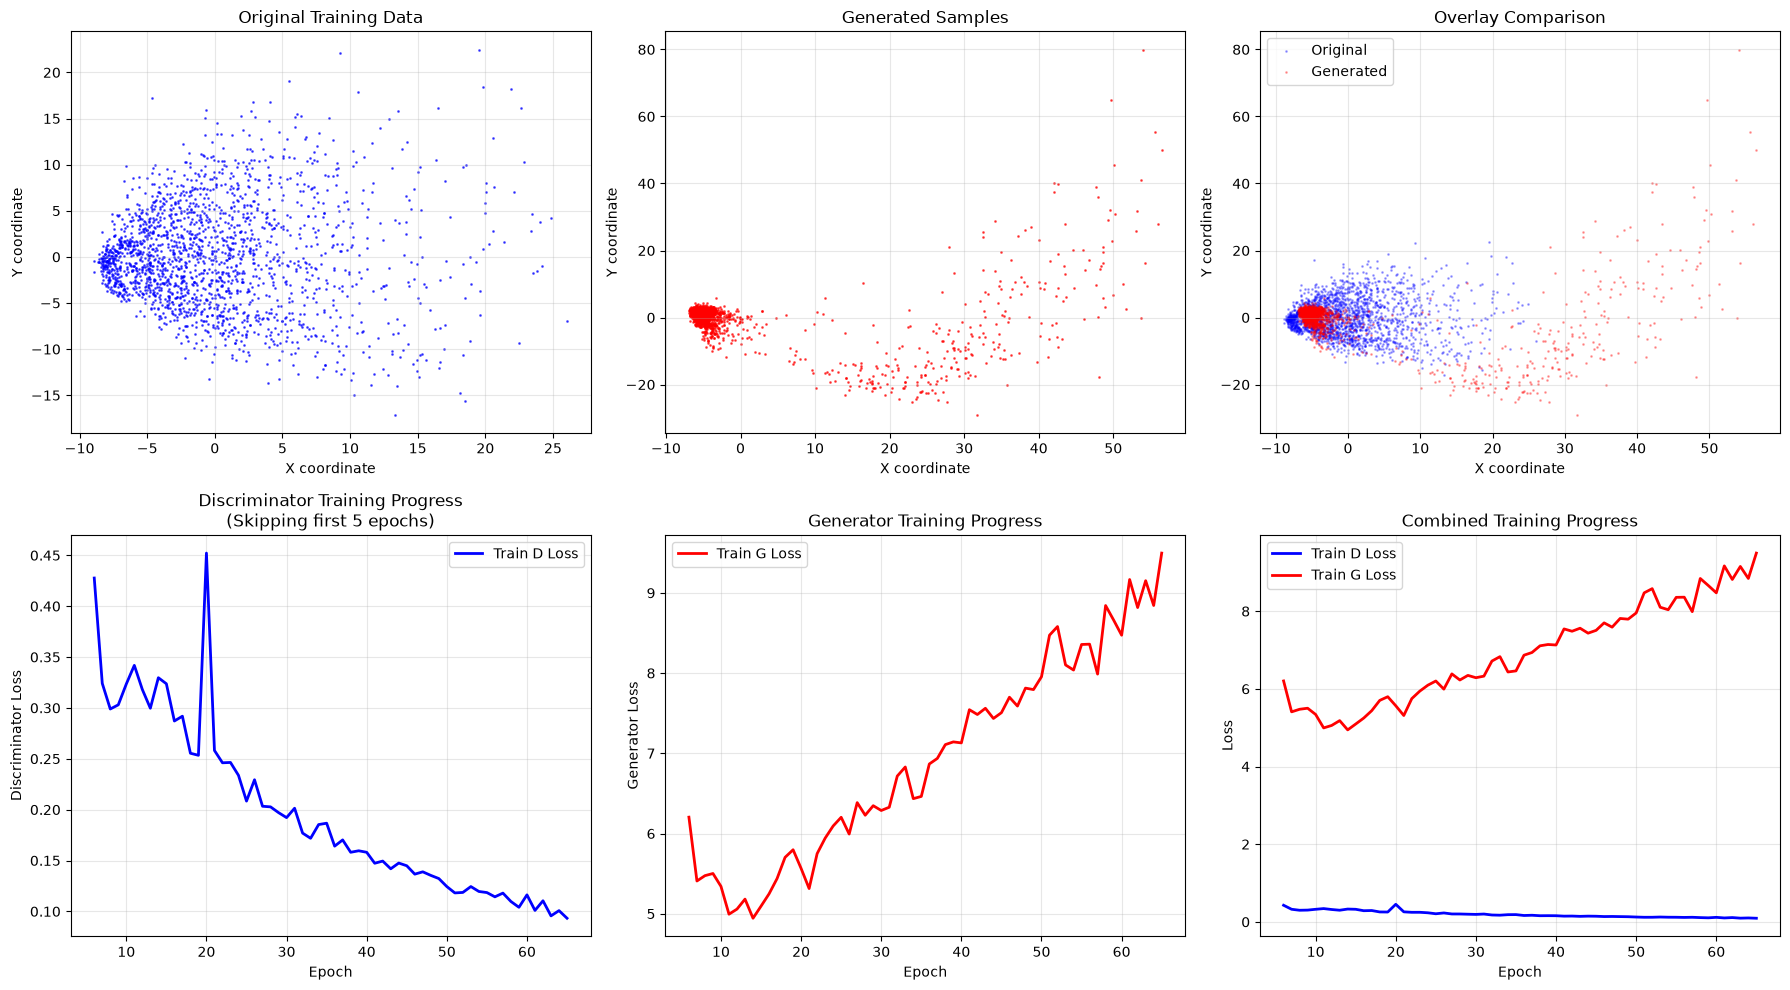

📈 Epoch 65 Summary:
   Train D Loss: 0.0933, Val D Loss: 0.1310
   Train G Loss: 9.4962, Val G Loss: 6.2313

📊 Epoch 66/100
----------------------------------------
Epoch: 66 [0/60000 (0%)]	D_loss: 0.082268	G_loss: 6.397359
Epoch: 66 [6400/60000 (11%)]	D_loss: 0.080421	G_loss: 5.194727
Epoch: 66 [12800/60000 (21%)]	D_loss: 0.161936	G_loss: 5.845510
Epoch: 66 [19200/60000 (32%)]	D_loss: 0.035025	G_loss: 9.108374
Epoch: 66 [25600/60000 (43%)]	D_loss: 0.055268	G_loss: 10.389624
Epoch: 66 [32000/60000 (53%)]	D_loss: 0.056747	G_loss: 6.885238
Epoch: 66 [38400/60000 (64%)]	D_loss: 0.096621	G_loss: 6.509831
Epoch: 66 [44800/60000 (75%)]	D_loss: 0.102677	G_loss: 6.458646
Epoch: 66 [51200/60000 (85%)]	D_loss: 0.142627	G_loss: 6.597205
Epoch: 66 [57600/60000 (96%)]	D_loss: 0.038450	G_loss: 7.316681
====> Epoch: 66 Train D_loss: 0.0944, Train G_loss: 8.8167
====> Epoch: 66 Val D_loss: 0.1272, Val G_loss: 5.6665
📈 Epoch 66 Summary:
   Train D Loss: 0.0944, Val D Loss: 0.1272
   Train G Loss: 8.816

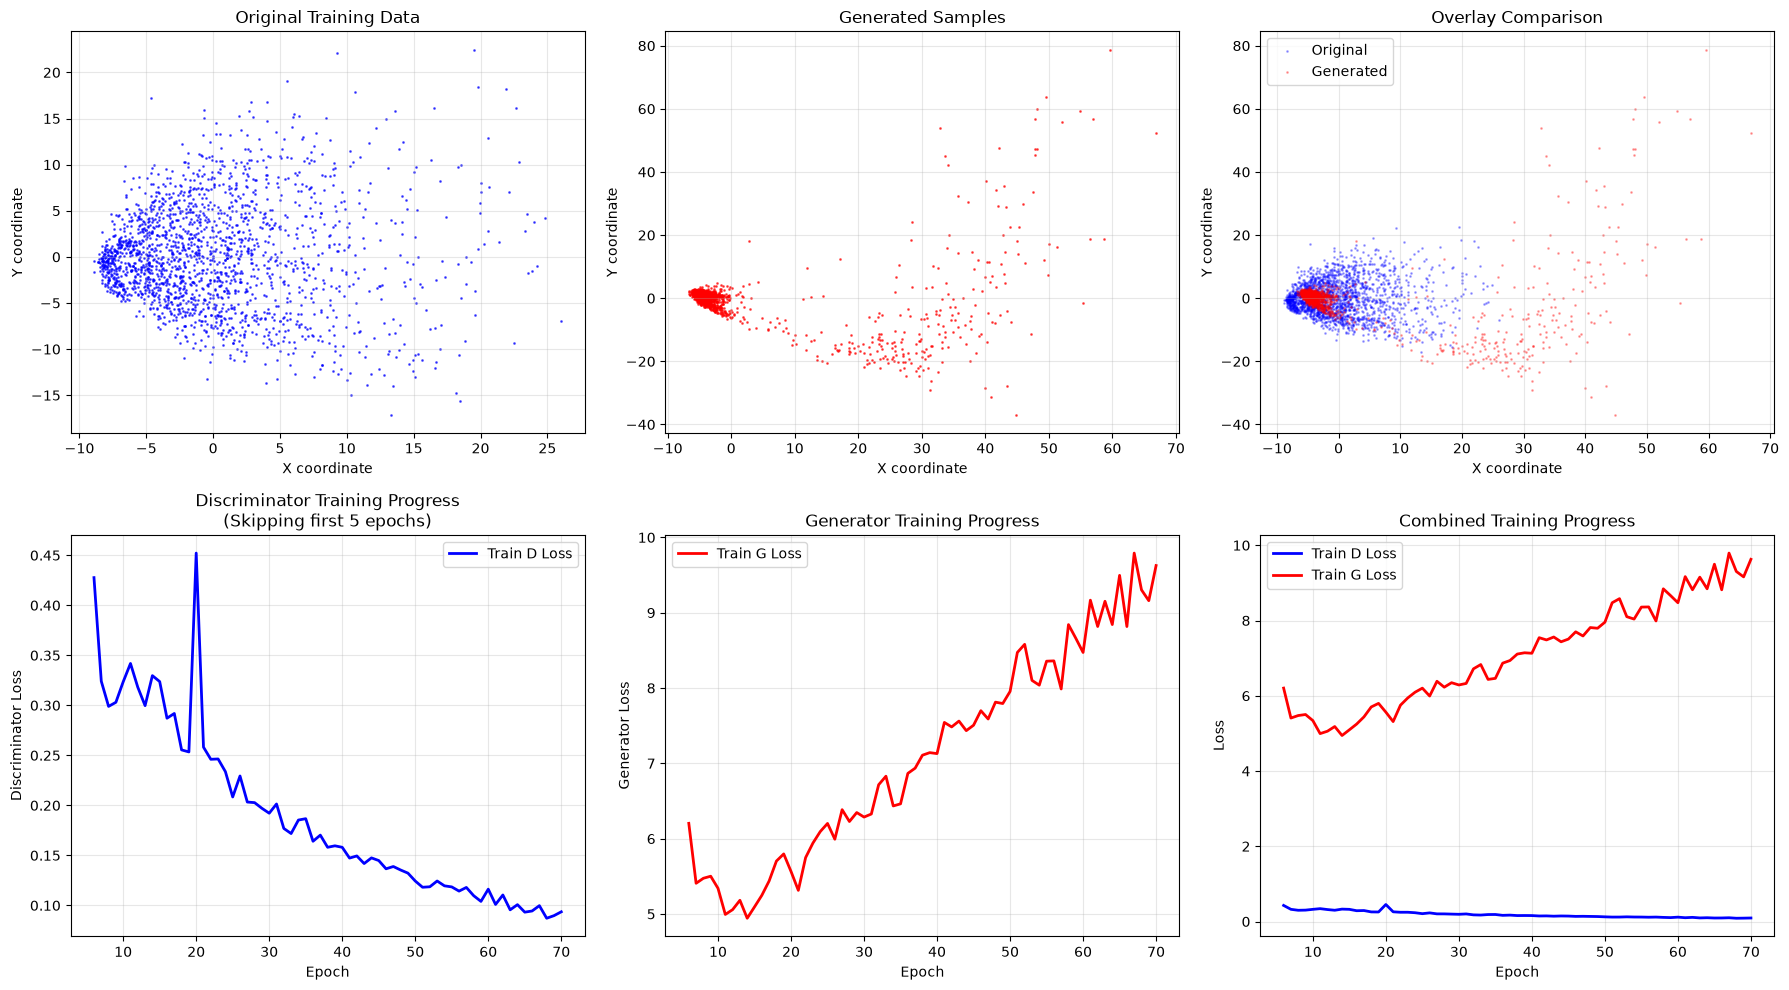

📈 Epoch 70 Summary:
   Train D Loss: 0.0936, Val D Loss: 0.1735
   Train G Loss: 9.6264, Val G Loss: 9.3037

📊 Epoch 71/100
----------------------------------------
Epoch: 71 [0/60000 (0%)]	D_loss: 0.065821	G_loss: 10.598503
Epoch: 71 [6400/60000 (11%)]	D_loss: 0.043664	G_loss: 5.275539
Epoch: 71 [12800/60000 (21%)]	D_loss: 0.052879	G_loss: 10.178085
Epoch: 71 [19200/60000 (32%)]	D_loss: 0.061640	G_loss: 7.860554
Epoch: 71 [25600/60000 (43%)]	D_loss: 0.084690	G_loss: 11.436316
Epoch: 71 [32000/60000 (53%)]	D_loss: 0.142272	G_loss: 5.253202
Epoch: 71 [38400/60000 (64%)]	D_loss: 0.050576	G_loss: 8.287257
Epoch: 71 [44800/60000 (75%)]	D_loss: 0.047122	G_loss: 8.014790
Epoch: 71 [51200/60000 (85%)]	D_loss: 0.054595	G_loss: 7.938099
Epoch: 71 [57600/60000 (96%)]	D_loss: 0.032956	G_loss: 7.002922
====> Epoch: 71 Train D_loss: 0.0827, Train G_loss: 9.9704
====> Epoch: 71 Val D_loss: 0.1676, Val G_loss: 12.0962
📈 Epoch 71 Summary:
   Train D Loss: 0.0827, Val D Loss: 0.1676
   Train G Loss: 9.

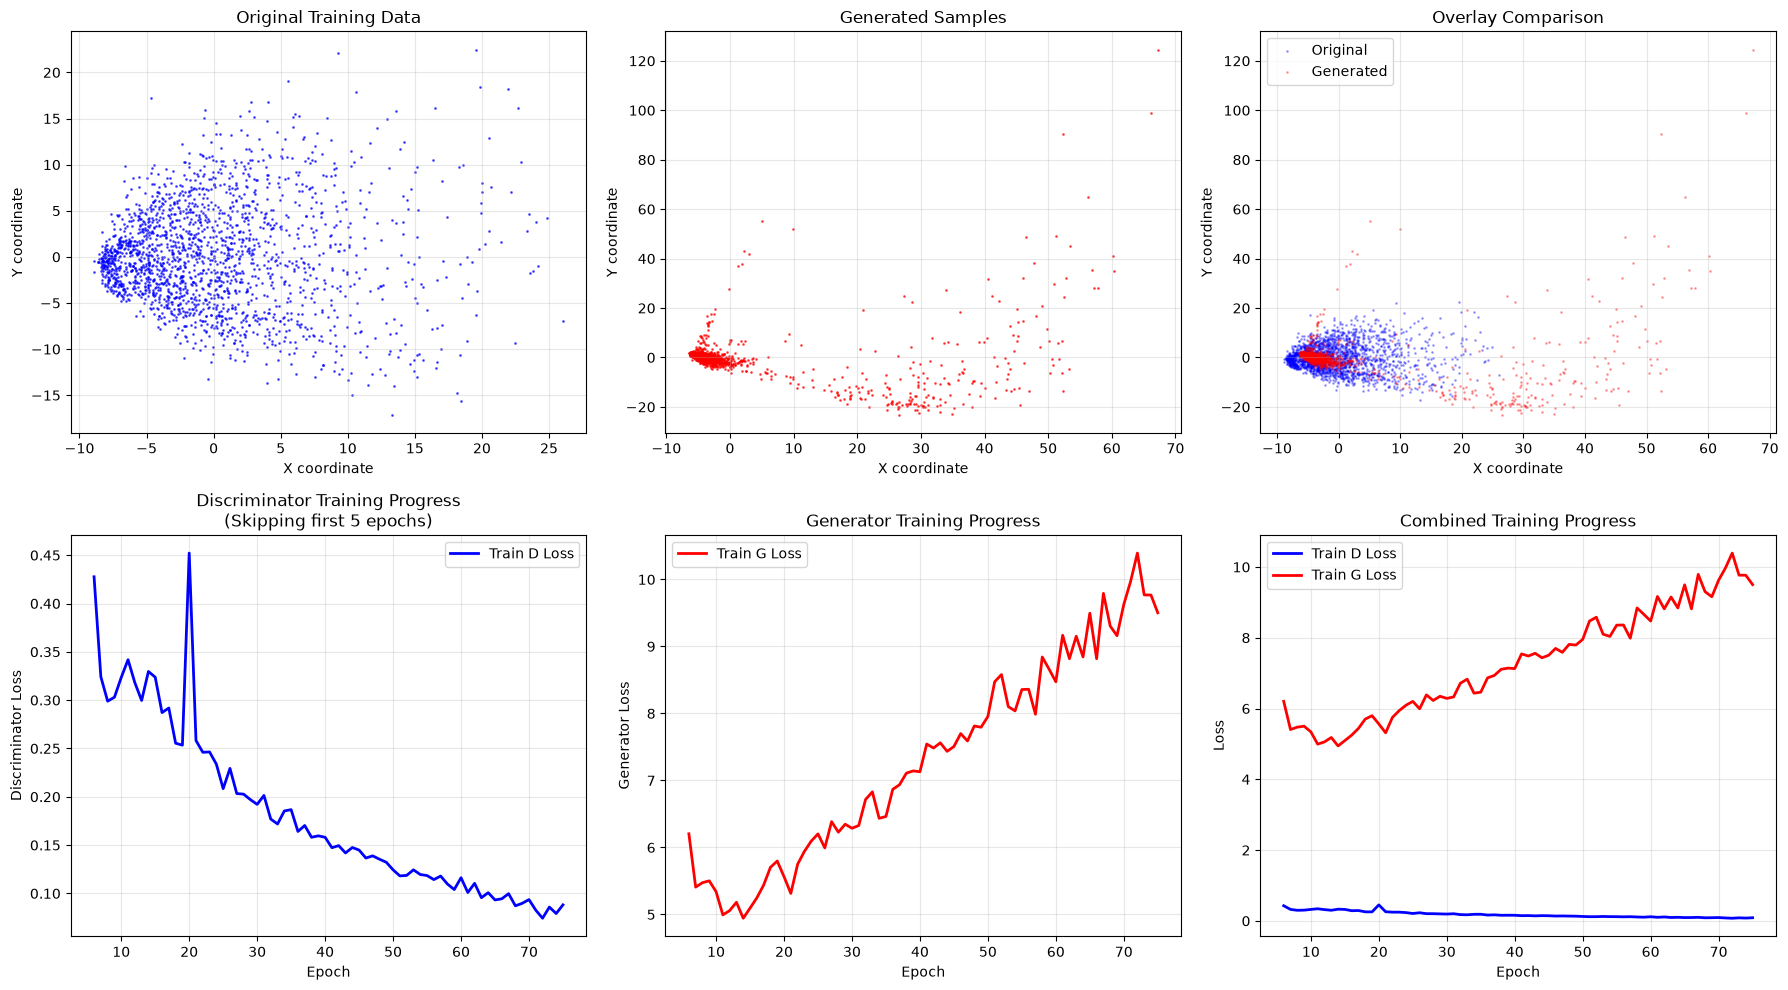

📈 Epoch 75 Summary:
   Train D Loss: 0.0881, Val D Loss: 0.1026
   Train G Loss: 9.5023, Val G Loss: 11.6489

📊 Epoch 76/100
----------------------------------------
Epoch: 76 [0/60000 (0%)]	D_loss: 0.040378	G_loss: 10.787829
Epoch: 76 [6400/60000 (11%)]	D_loss: 0.013595	G_loss: 9.950819
Epoch: 76 [12800/60000 (21%)]	D_loss: 0.023982	G_loss: 11.017891
Epoch: 76 [19200/60000 (32%)]	D_loss: 0.037889	G_loss: 7.579538
Epoch: 76 [25600/60000 (43%)]	D_loss: 0.163858	G_loss: 8.597031
Epoch: 76 [32000/60000 (53%)]	D_loss: 0.075076	G_loss: 9.323095
Epoch: 76 [38400/60000 (64%)]	D_loss: 0.115048	G_loss: 6.376047
Epoch: 76 [44800/60000 (75%)]	D_loss: 0.017232	G_loss: 7.981085
Epoch: 76 [51200/60000 (85%)]	D_loss: 0.044777	G_loss: 13.383365
Epoch: 76 [57600/60000 (96%)]	D_loss: 0.078169	G_loss: 6.378453
====> Epoch: 76 Train D_loss: 0.0755, Train G_loss: 10.4755
====> Epoch: 76 Val D_loss: 0.0913, Val G_loss: 9.9530
📈 Epoch 76 Summary:
   Train D Loss: 0.0755, Val D Loss: 0.0913
   Train G Loss: 1

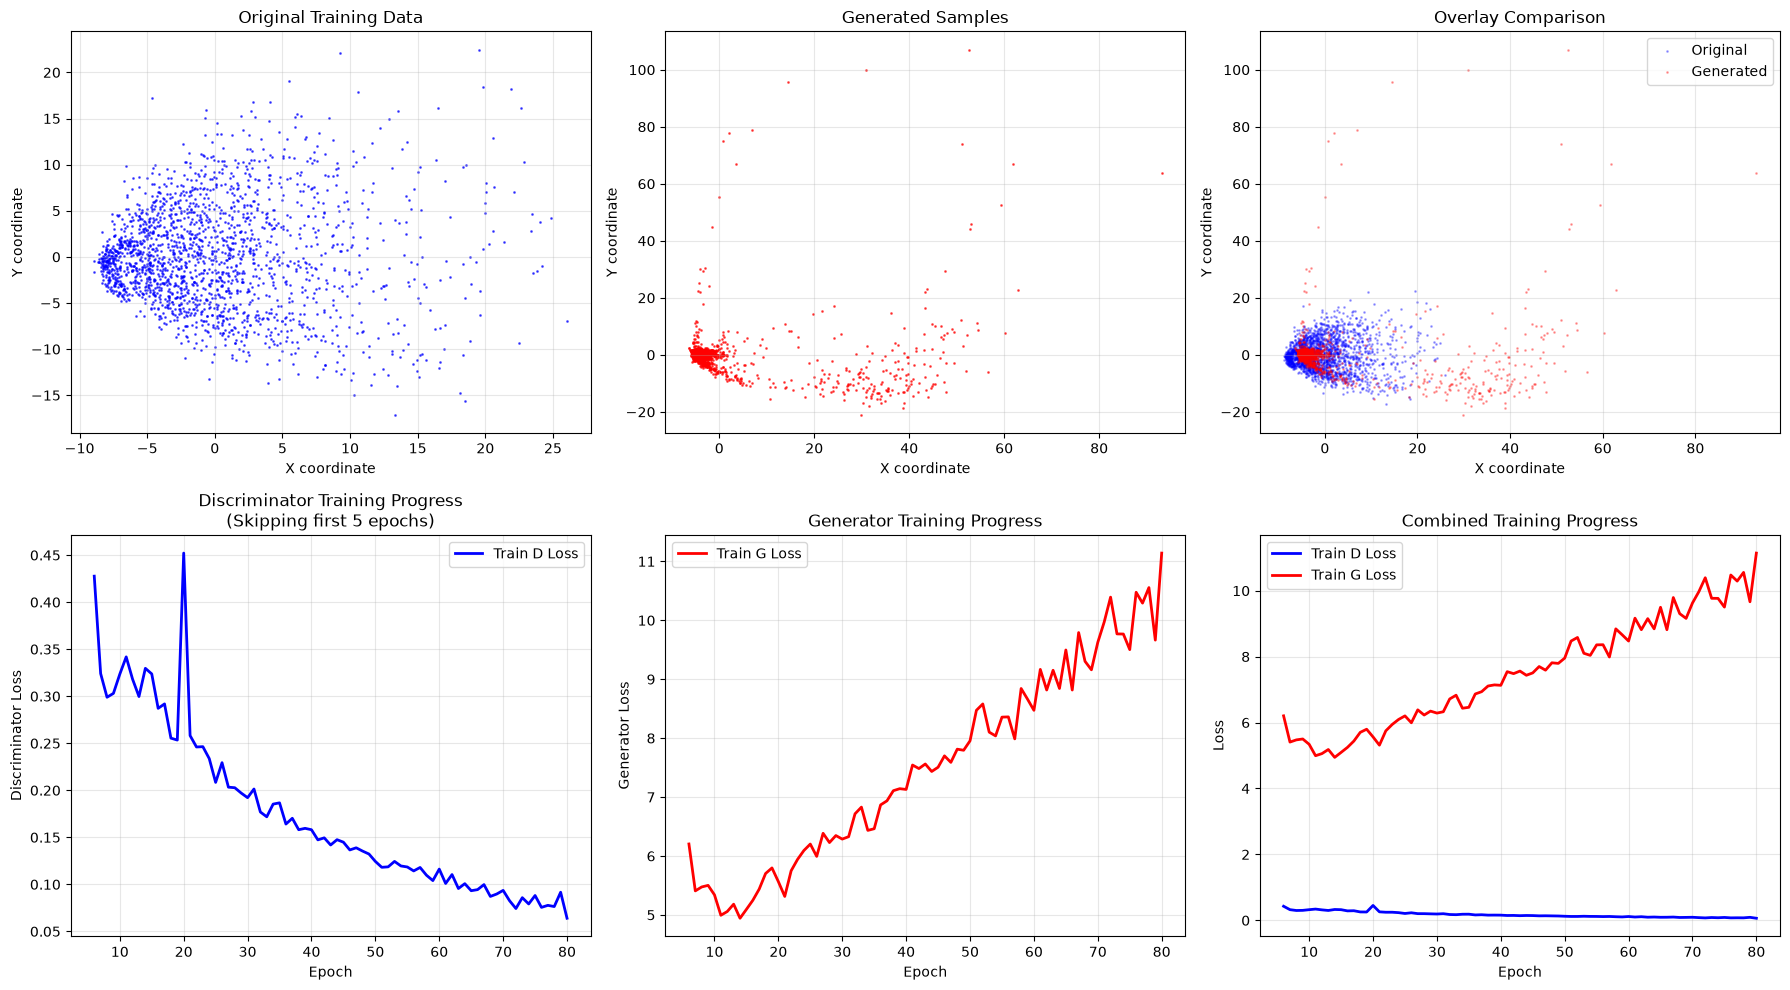

📈 Epoch 80 Summary:
   Train D Loss: 0.0640, Val D Loss: 0.1010
   Train G Loss: 11.1404, Val G Loss: 11.0750

📊 Epoch 81/100
----------------------------------------
Epoch: 81 [0/60000 (0%)]	D_loss: 0.038526	G_loss: 11.115134
Epoch: 81 [6400/60000 (11%)]	D_loss: 0.123910	G_loss: 10.415428
Epoch: 81 [12800/60000 (21%)]	D_loss: 0.042554	G_loss: 7.213428
Epoch: 81 [19200/60000 (32%)]	D_loss: 0.058228	G_loss: 20.585501
Epoch: 81 [25600/60000 (43%)]	D_loss: 0.013068	G_loss: 9.874859
Epoch: 81 [32000/60000 (53%)]	D_loss: 0.121493	G_loss: 10.725008
Epoch: 81 [38400/60000 (64%)]	D_loss: 0.138253	G_loss: 6.236061
Epoch: 81 [44800/60000 (75%)]	D_loss: 0.009280	G_loss: 14.720570
Epoch: 81 [51200/60000 (85%)]	D_loss: 0.024090	G_loss: 10.745198
Epoch: 81 [57600/60000 (96%)]	D_loss: 0.021441	G_loss: 9.754936
====> Epoch: 81 Train D_loss: 0.0758, Train G_loss: 11.1253
====> Epoch: 81 Val D_loss: 0.1033, Val G_loss: 16.4235
📈 Epoch 81 Summary:
   Train D Loss: 0.0758, Val D Loss: 0.1033
   Train G Lo

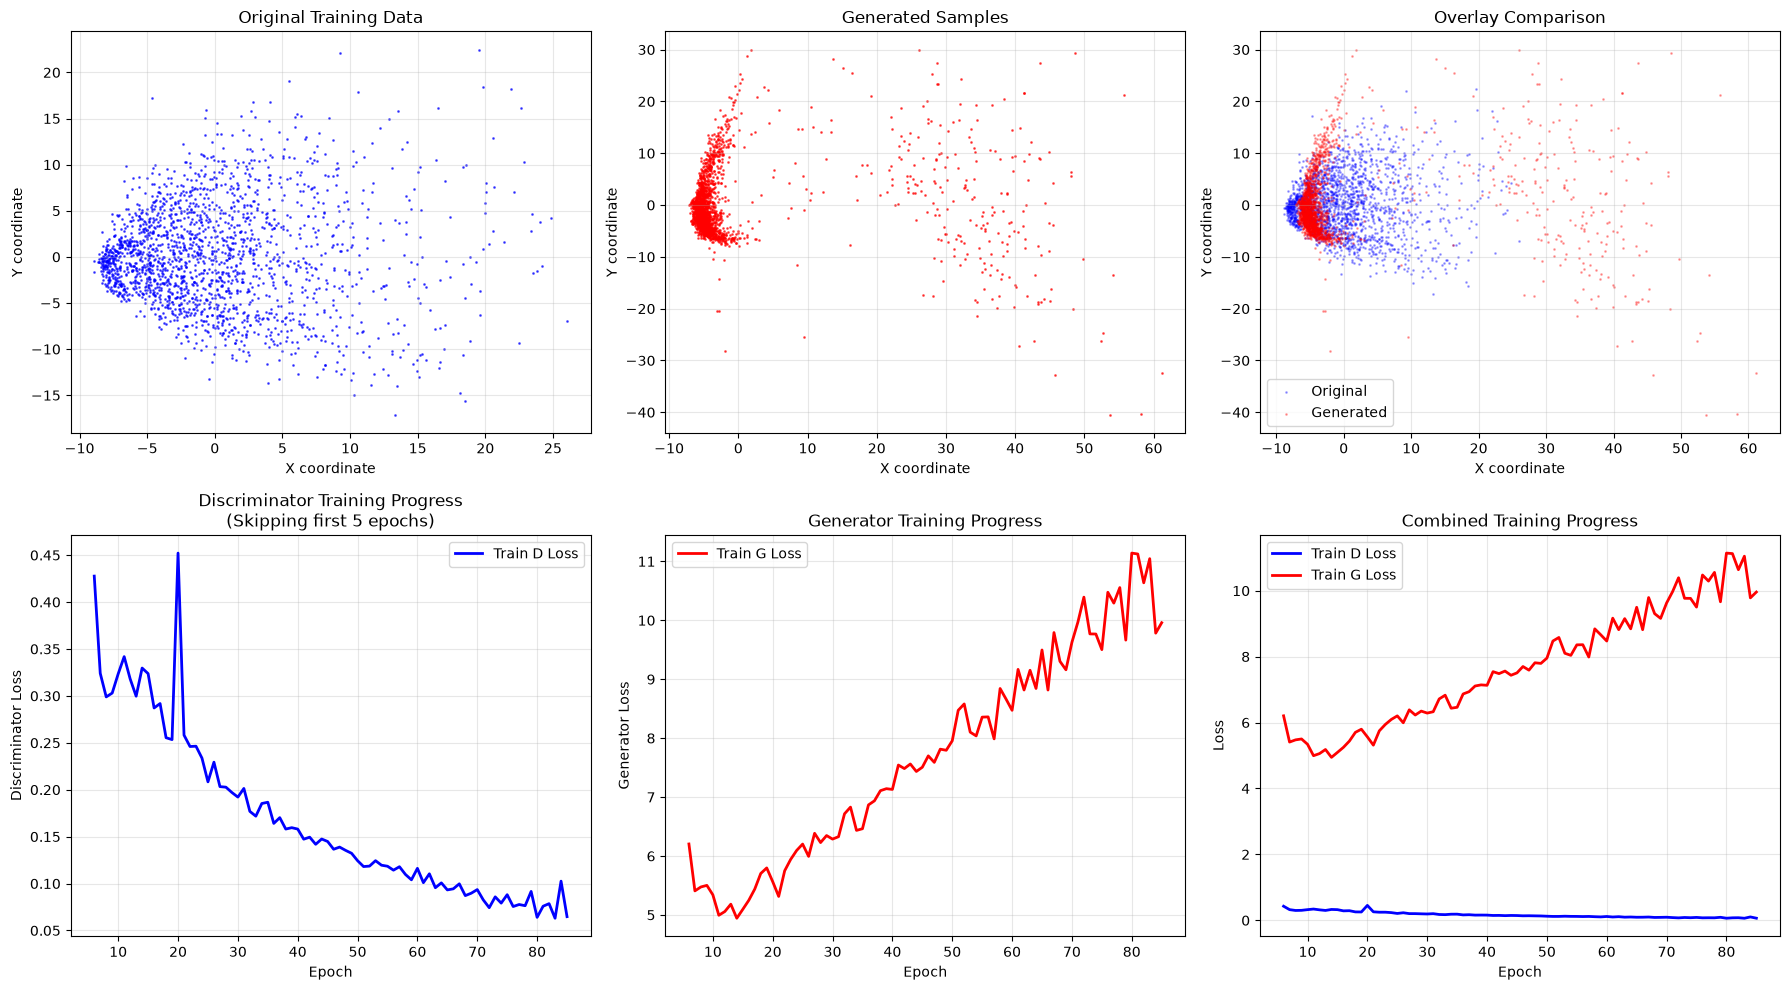

📈 Epoch 85 Summary:
   Train D Loss: 0.0647, Val D Loss: 0.0778
   Train G Loss: 9.9588, Val G Loss: 5.8620

📊 Epoch 86/100
----------------------------------------
Epoch: 86 [0/60000 (0%)]	D_loss: 0.026072	G_loss: 6.681671
Epoch: 86 [6400/60000 (11%)]	D_loss: 0.032517	G_loss: 6.363664
Epoch: 86 [12800/60000 (21%)]	D_loss: 0.034013	G_loss: 10.164305
Epoch: 86 [19200/60000 (32%)]	D_loss: 0.111685	G_loss: 20.708271
Epoch: 86 [25600/60000 (43%)]	D_loss: 0.092773	G_loss: 5.990104
Epoch: 86 [32000/60000 (53%)]	D_loss: 0.051767	G_loss: 13.584565
Epoch: 86 [38400/60000 (64%)]	D_loss: 0.043663	G_loss: 8.734739
Epoch: 86 [44800/60000 (75%)]	D_loss: 0.025136	G_loss: 12.238152
Epoch: 86 [51200/60000 (85%)]	D_loss: 0.062582	G_loss: 14.439891
Epoch: 86 [57600/60000 (96%)]	D_loss: 0.075121	G_loss: 9.688792
====> Epoch: 86 Train D_loss: 0.0674, Train G_loss: 10.6405
====> Epoch: 86 Val D_loss: 0.0677, Val G_loss: 10.9552
📈 Epoch 86 Summary:
   Train D Loss: 0.0674, Val D Loss: 0.0677
   Train G Loss:

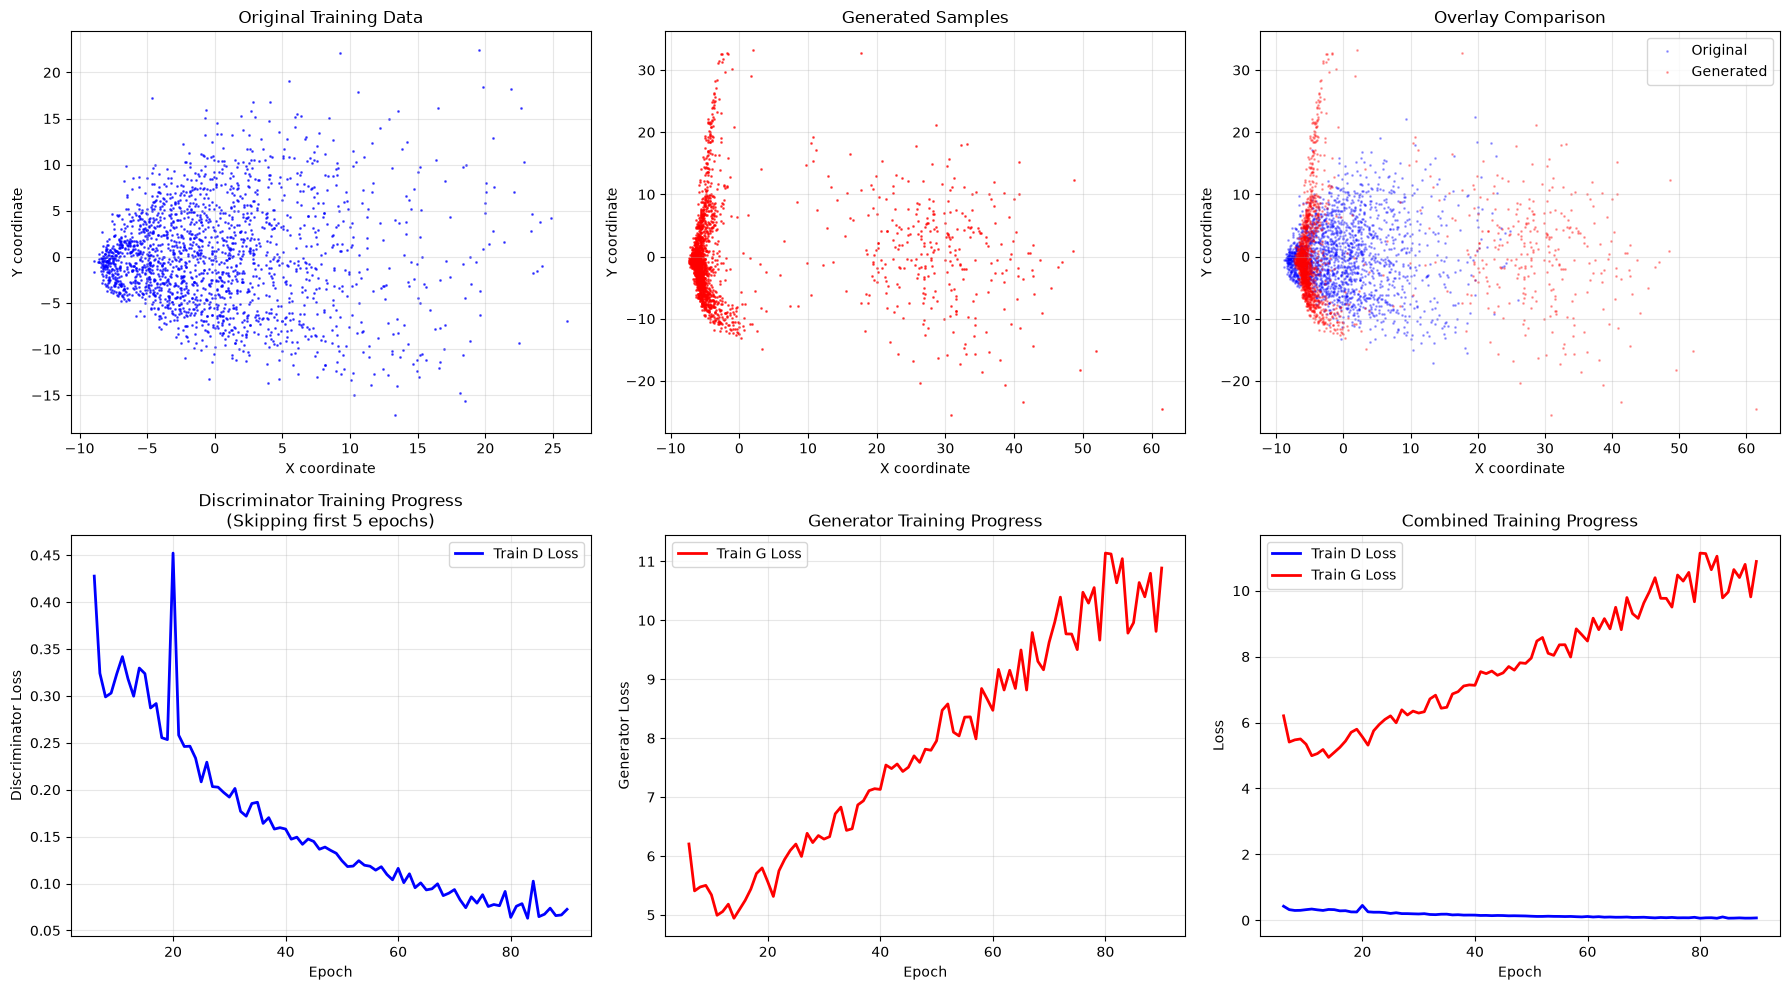

📈 Epoch 90 Summary:
   Train D Loss: 0.0726, Val D Loss: 0.1171
   Train G Loss: 10.8870, Val G Loss: 6.5697

📊 Epoch 91/100
----------------------------------------
Epoch: 91 [0/60000 (0%)]	D_loss: 0.081511	G_loss: 6.762369
Epoch: 91 [6400/60000 (11%)]	D_loss: 0.053175	G_loss: 35.198002
Epoch: 91 [12800/60000 (21%)]	D_loss: 0.042878	G_loss: 12.113682
Epoch: 91 [19200/60000 (32%)]	D_loss: 0.029403	G_loss: 20.430798
Epoch: 91 [25600/60000 (43%)]	D_loss: 0.029067	G_loss: 8.985987
Epoch: 91 [32000/60000 (53%)]	D_loss: 0.032507	G_loss: 20.114143
Epoch: 91 [38400/60000 (64%)]	D_loss: 0.147850	G_loss: 24.214525
Epoch: 91 [44800/60000 (75%)]	D_loss: 0.020334	G_loss: 17.293919
Epoch: 91 [51200/60000 (85%)]	D_loss: 0.036232	G_loss: 21.919144
Epoch: 91 [57600/60000 (96%)]	D_loss: 0.029456	G_loss: 10.073793
====> Epoch: 91 Train D_loss: 0.0664, Train G_loss: 12.0890
====> Epoch: 91 Val D_loss: 0.1690, Val G_loss: 8.2032
📈 Epoch 91 Summary:
   Train D Loss: 0.0664, Val D Loss: 0.1690
   Train G Lo

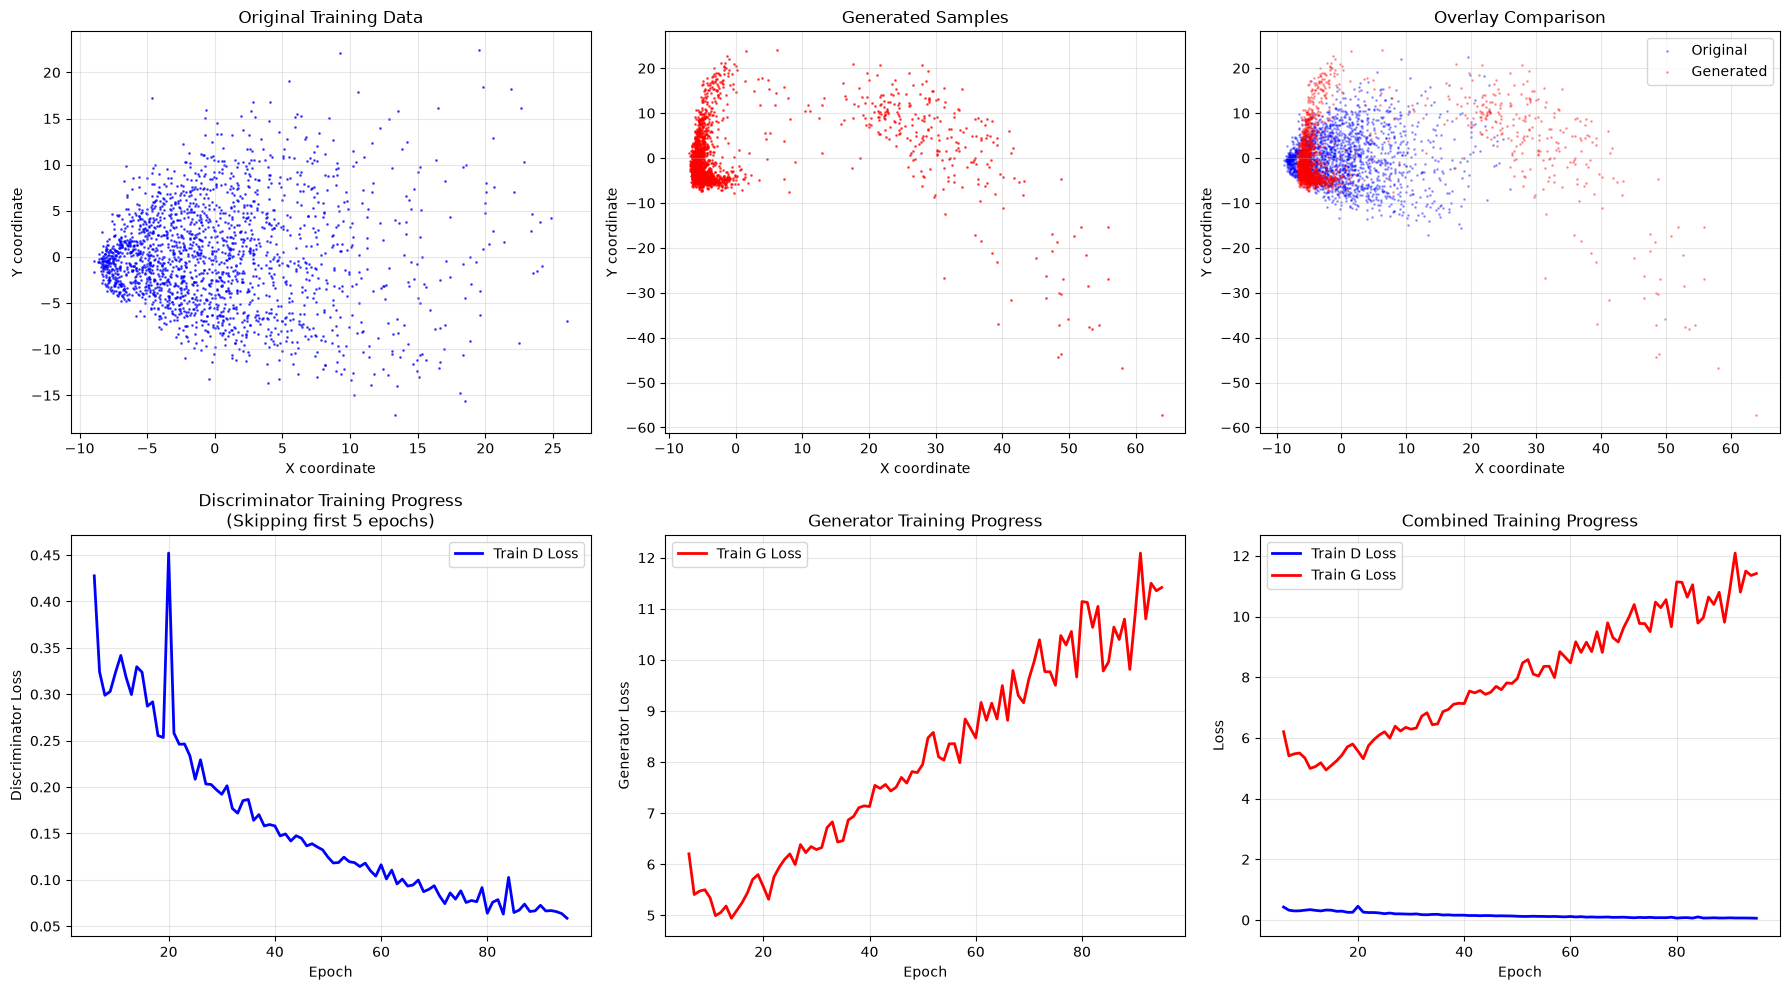

📈 Epoch 95 Summary:
   Train D Loss: 0.0586, Val D Loss: 0.0781
   Train G Loss: 11.4159, Val G Loss: 9.1840

📊 Epoch 96/100
----------------------------------------
Epoch: 96 [0/60000 (0%)]	D_loss: 0.033423	G_loss: 10.182144
Epoch: 96 [6400/60000 (11%)]	D_loss: 0.070653	G_loss: 8.946838
Epoch: 96 [12800/60000 (21%)]	D_loss: 0.116075	G_loss: 9.006582
Epoch: 96 [19200/60000 (32%)]	D_loss: 0.024663	G_loss: 16.879707
Epoch: 96 [25600/60000 (43%)]	D_loss: 0.020565	G_loss: 11.299189
Epoch: 96 [32000/60000 (53%)]	D_loss: 0.013596	G_loss: 11.467588
Epoch: 96 [38400/60000 (64%)]	D_loss: 0.086275	G_loss: 11.396747
Epoch: 96 [44800/60000 (75%)]	D_loss: 0.056611	G_loss: 8.850318
Epoch: 96 [51200/60000 (85%)]	D_loss: 0.107944	G_loss: 10.553958
Epoch: 96 [57600/60000 (96%)]	D_loss: 0.028961	G_loss: 9.408576
====> Epoch: 96 Train D_loss: 0.0637, Train G_loss: 11.5057
====> Epoch: 96 Val D_loss: 0.0781, Val G_loss: 16.3116
📈 Epoch 96 Summary:
   Train D Loss: 0.0637, Val D Loss: 0.0781
   Train G Los

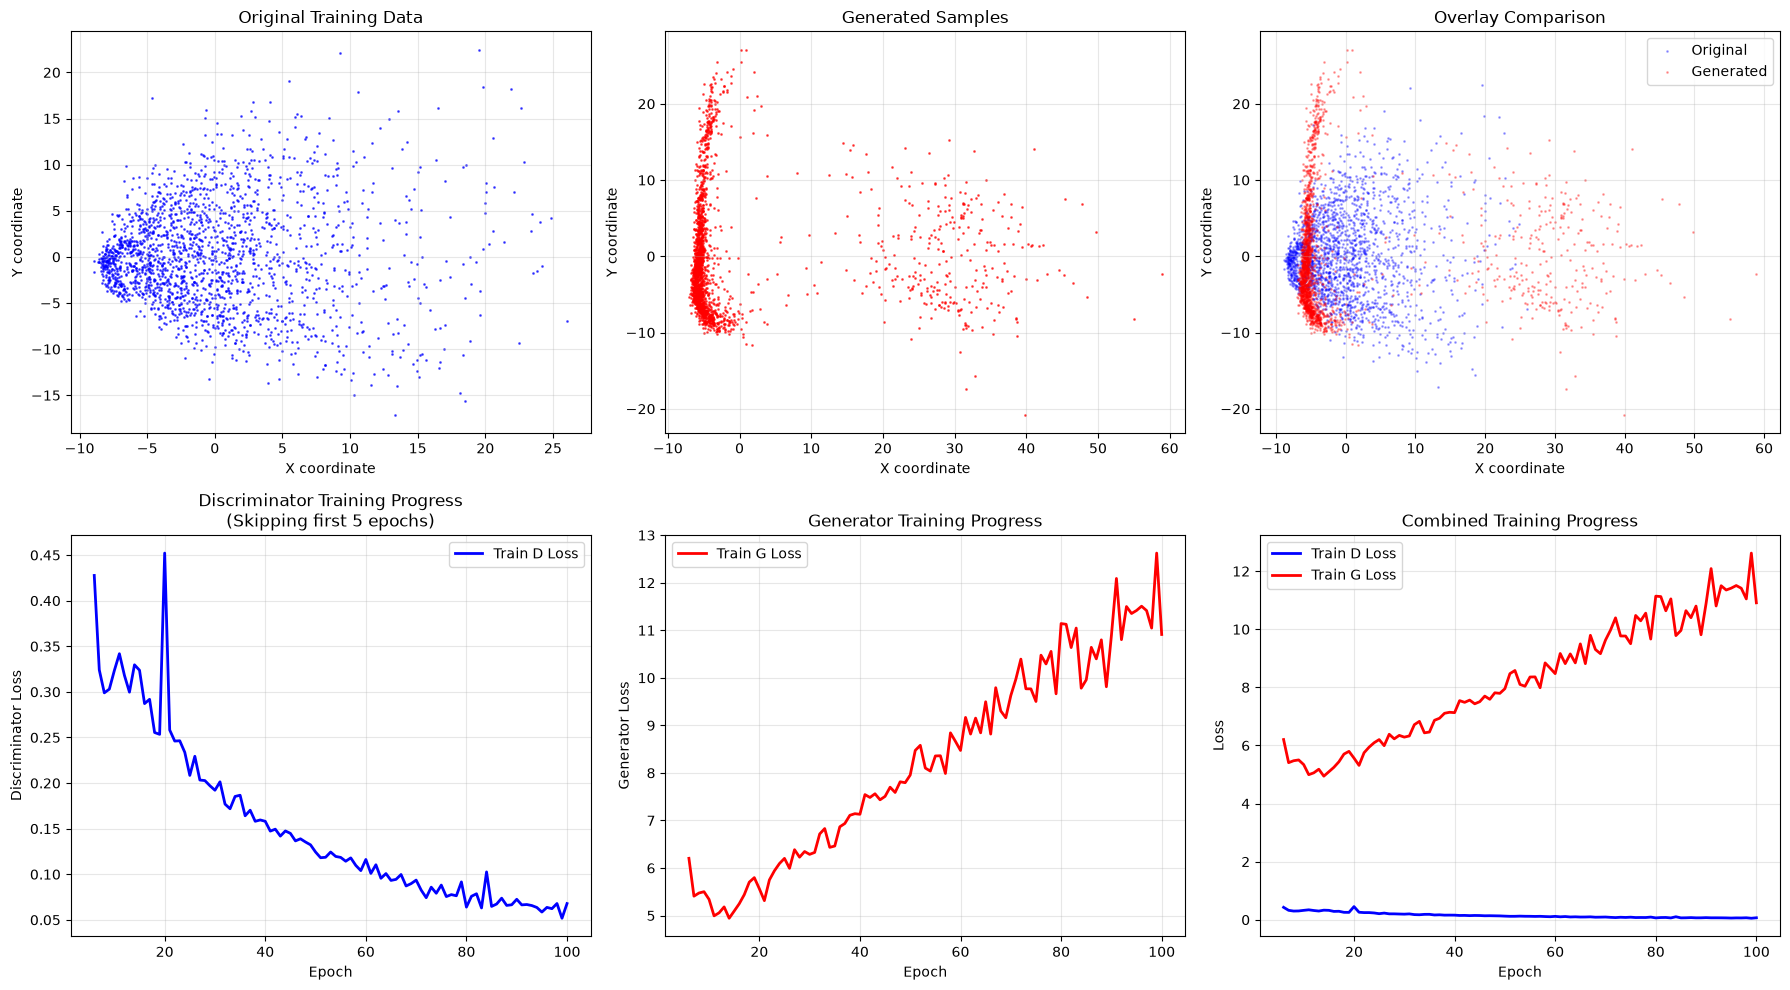

📈 Epoch 100 Summary:
   Train D Loss: 0.0679, Val D Loss: 0.0837
   Train G Loss: 10.9110, Val G Loss: 6.7951

🎉 Training completed!

🎨 Final comprehensive visualization:


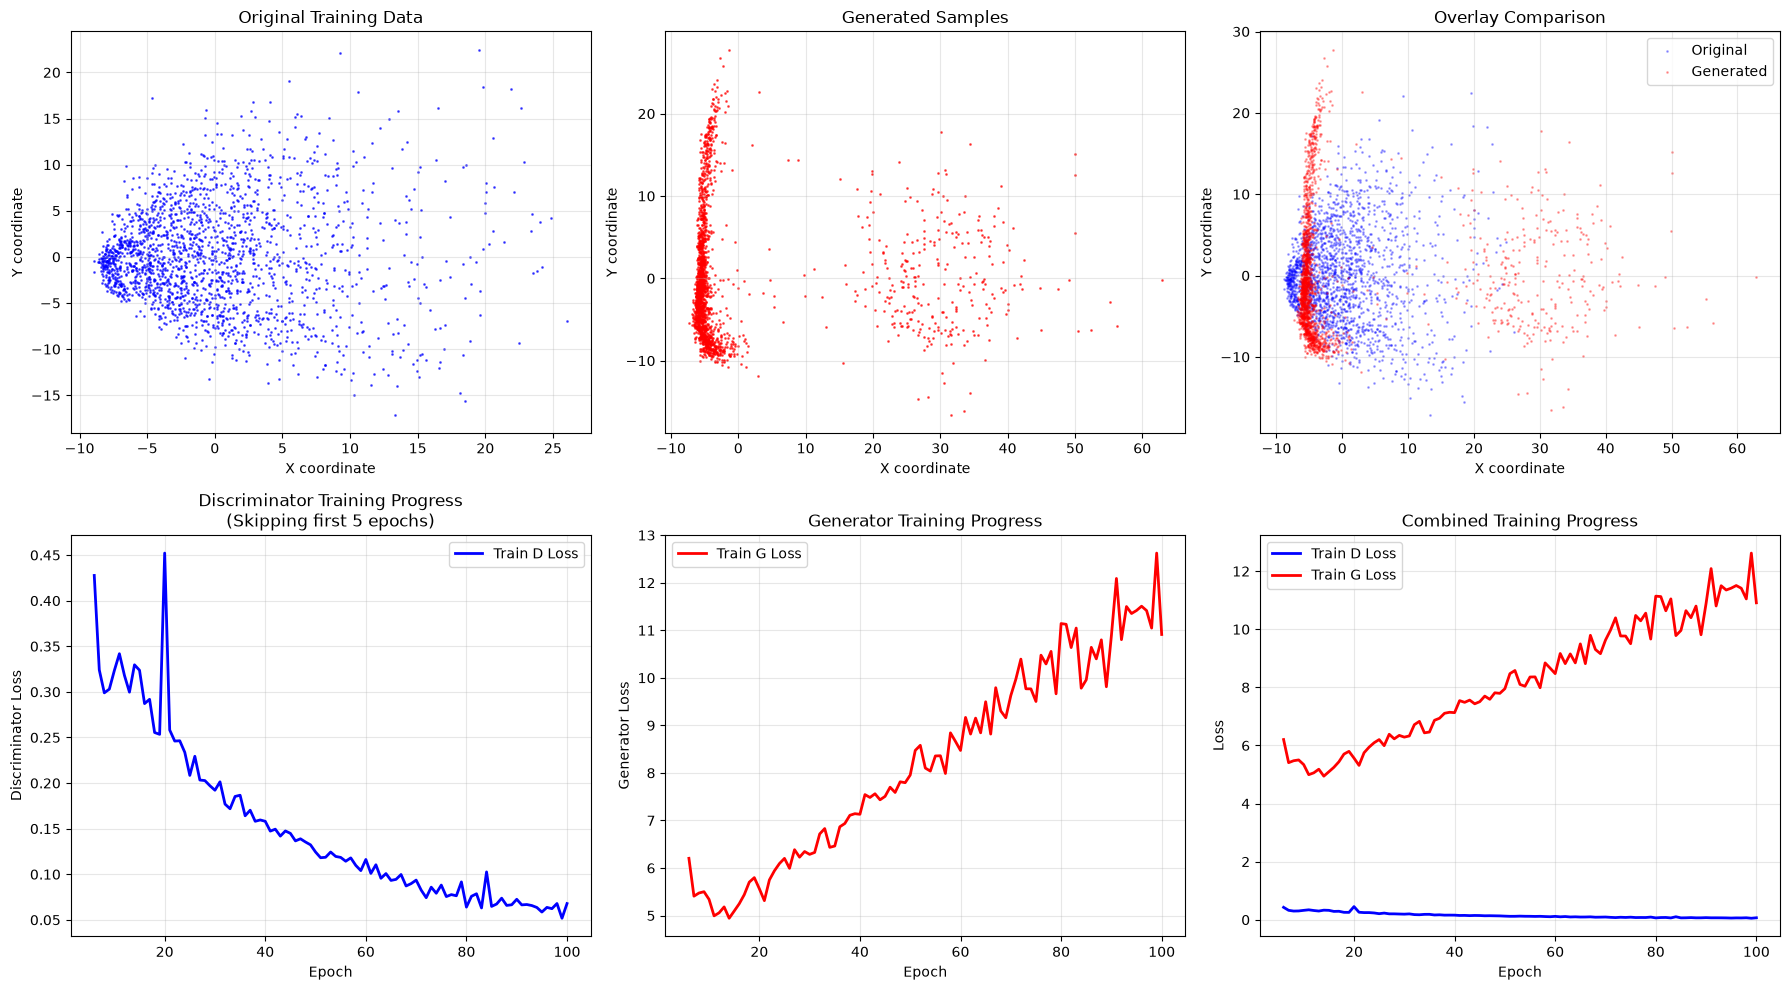

In [14]:
# Training loop
print("🎯 Starting GAN training...")
print("=" * 60)

# Lists to track training progress
train_d_losses = []
train_g_losses = []
val_d_losses = []
val_g_losses = []

# Show initial state (before training)
print("📊 Initial state (before training):")

for epoch in range(1, EPOCHS + 1):
    print(f"\n📊 Epoch {epoch}/{EPOCHS}")
    print("-" * 40)
    
    # Train for one epoch with validation
    train_d_loss, train_g_loss, val_d_loss, val_g_loss = train_epoch_with_validation(epoch)
    
    # Track losses
    train_d_losses.append(train_d_loss)
    train_g_losses.append(train_g_loss)
    val_d_losses.append(val_d_loss)
    val_g_losses.append(val_g_loss)
    
    # Visualize progress every 5 epochs
    if epoch % SAVE_PLT_INTERVAL == 0:
        print(f"\n🎨 Visualizing progress at epoch {epoch}...")
        visualize_training_progress(epoch, train_d_losses, train_g_losses, val_d_losses, val_g_losses)
    
    print(f"📈 Epoch {epoch} Summary:")
    print(f"   Train D Loss: {train_d_loss:.4f}, Val D Loss: {val_d_loss:.4f}")
    print(f"   Train G Loss: {train_g_loss:.4f}, Val G Loss: {val_g_loss:.4f}")

print("\n🎉 Training completed!")
print("=" * 60)

# Save the trained models
# torch.save(generator.state_dict(), 'generator.pth')
# torch.save(discriminator.state_dict(), 'discriminator.pth')
# print("💾 Models saved as 'generator.pth' and 'discriminator.pth'")

# Final comprehensive visualization
print("\n🎨 Final comprehensive visualization:")
visualize_training_progress(EPOCHS, train_d_losses, train_g_losses, val_d_losses, val_g_losses)


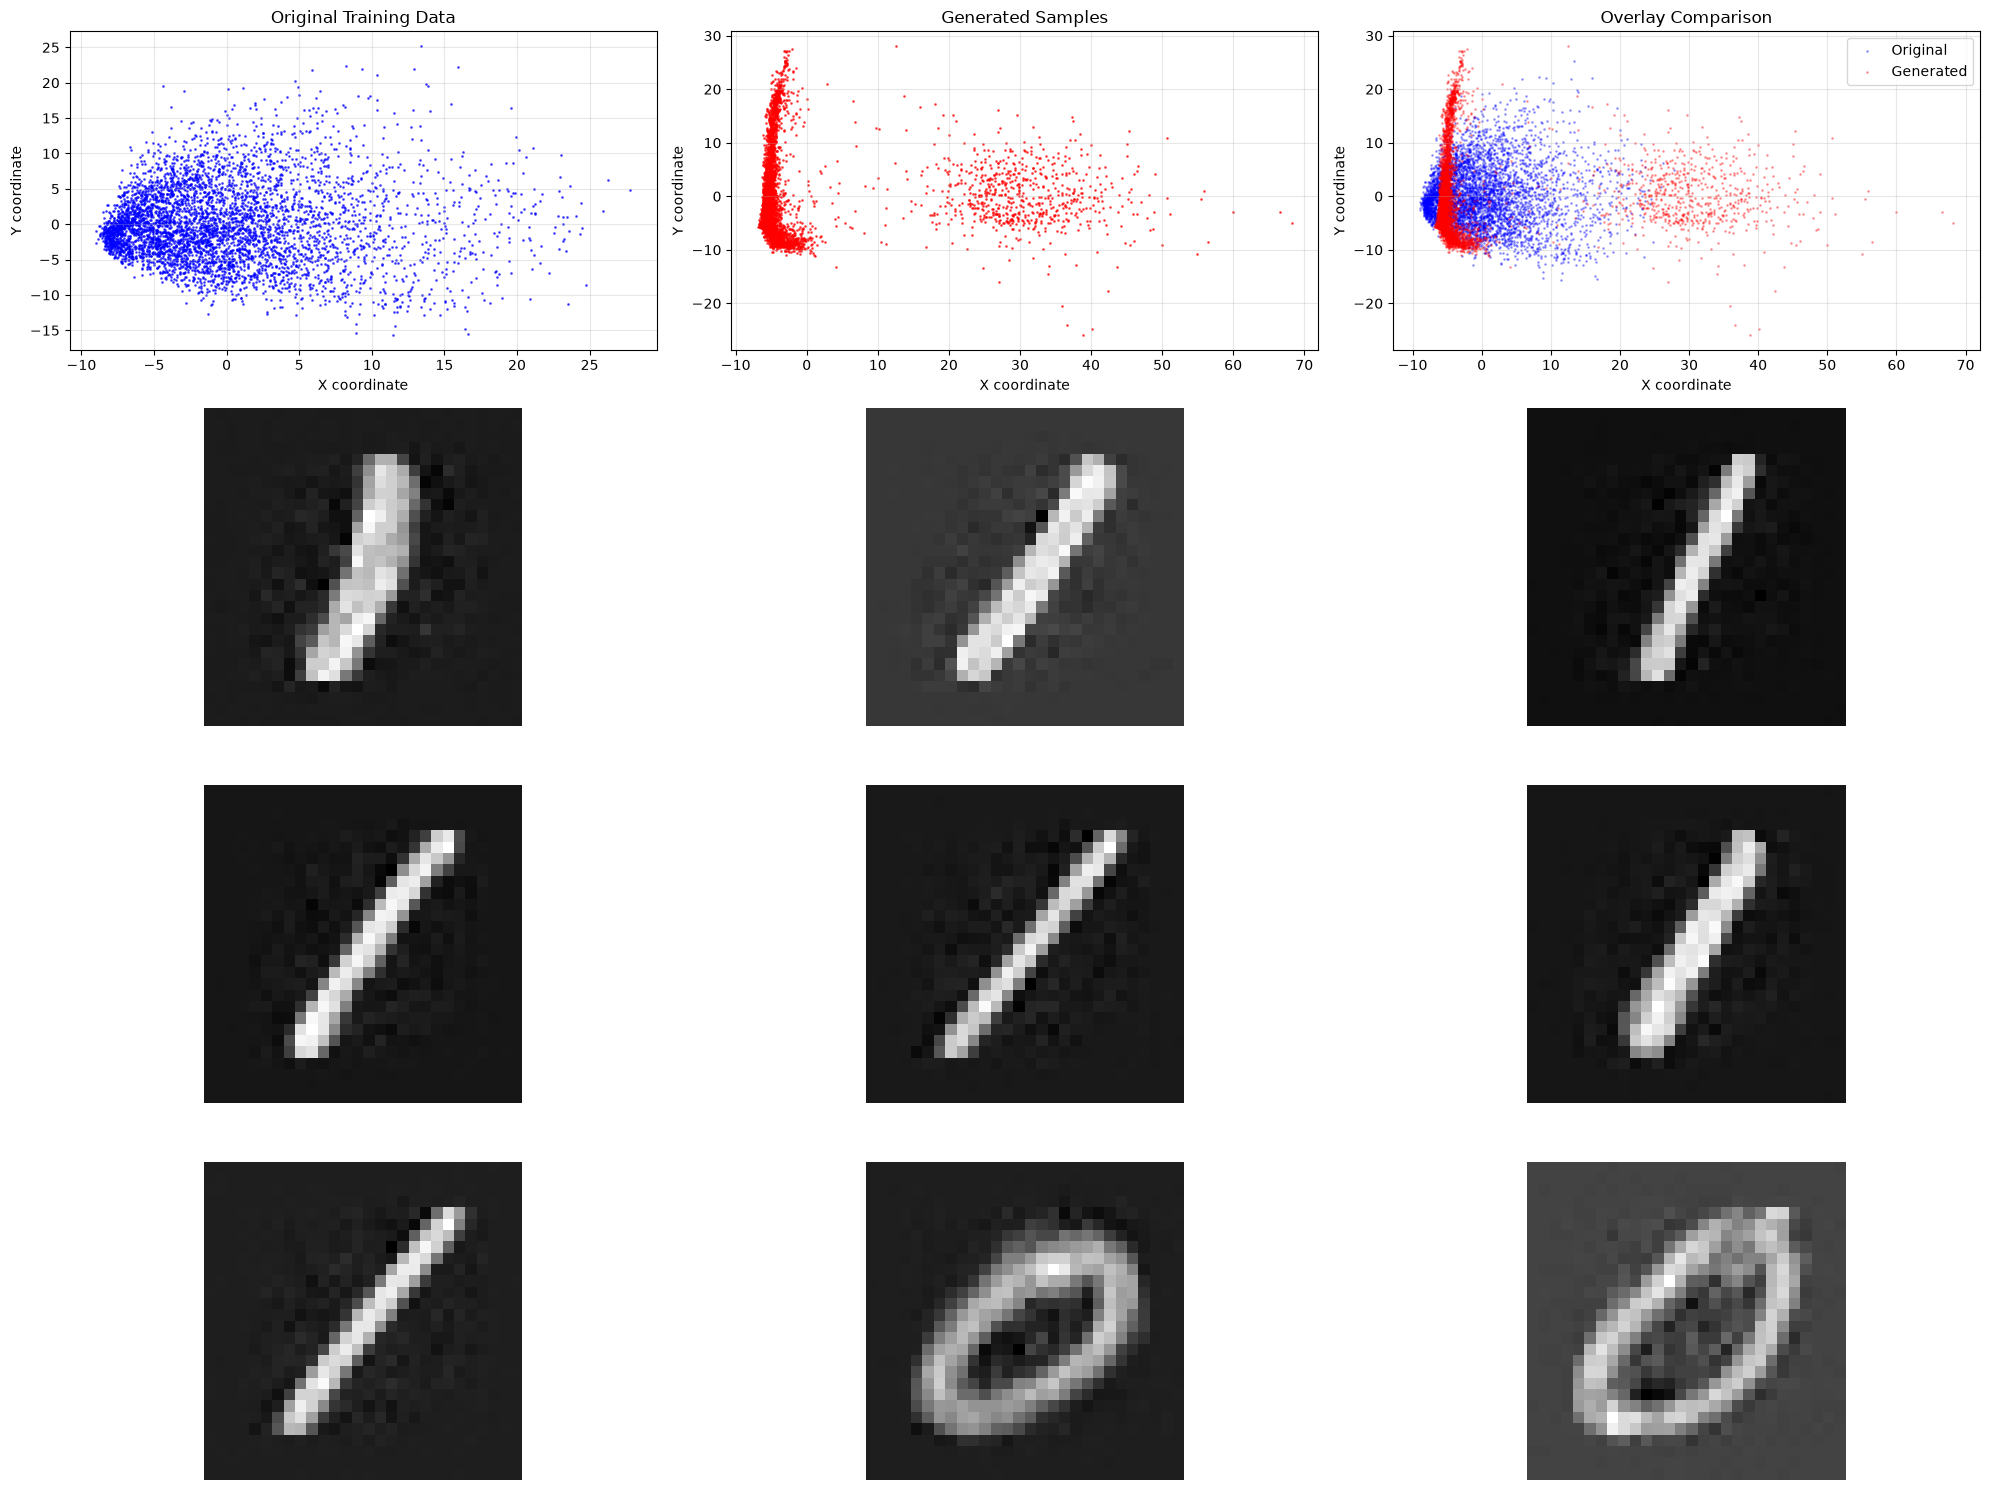

Real data confidence: 0.780
Fake data confidence: 0.009


In [15]:
# Generate a large number of samples
generated_samples = generate_samples(5000)

# Create comprehensive visualization
plt.figure(figsize=(20, 15))

train_data_reshaped = np.reshape(train_data.data[:5000], [5000, INPUT_DIM])
data_transformed = pca_fit(train_data_reshaped).transform(train_data_reshaped)
x_transformed = pca_fit(generated_samples).transform(generated_samples)

# Original training data
plt.subplot(4, 3, 1)
plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.6)
plt.title('Original Training Data')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.grid(True, alpha=0.3)

# Generated samples
plt.subplot(4, 3, 2)
plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.6)
plt.title('Generated Samples')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.grid(True, alpha=0.3)

# Overlay comparison
plt.subplot(4, 3, 3)
plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.3, label='Original')
plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.3, label='Generated')
plt.title('Overlay Comparison')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.legend()
plt.grid(True, alpha=0.3)


for i in range(9):
    plt.subplot(4, 3, 3 + i + 1)
    plt.imshow(np.reshape(generated_samples[i], [28, 28]).squeeze(), cmap="gray")
    plt.axis("off")

plt.tight_layout()
plt.show()


generator.eval()
discriminator.eval()
with torch.no_grad():
    # Test on real data
    real_batch = train_data.data[:100].to(device).float()
    real_batch = real_batch.reshape([100, INPUT_DIM])
    real_pred = discriminator(real_batch).mean().item()

    # Test on fake data
    noise = torch.randn(100, NOISE_DIM).to(device)
    fake_batch = generator(noise)
    fake_pred = discriminator(fake_batch).mean().item()

print(f'Real data confidence: {real_pred:.3f}')
print(f'Fake data confidence: {fake_pred:.3f}')
